# [14.2] I-JEPA from Scratch

**By the end of this notebook, you will have shown that an I-JEPA trained from scratch uses a visible object-class key to predict the latent target of a completely masked object on pixel-distinct scenes sharing all twelve object-position templates, because correct context reaches 100% object recovery while cyclically mismatched context reaches 0%, zero context raises latent loss, and an untrained predictor remains at chance.**

Training and evaluation share every semantic template; only background pixels differ. This is an exact teaching world, not ImageNet or checkpoint parity. The point is to build the asymmetric latent-prediction mechanism yourself, then falsify easier explanations.

## Core Question

When the target object is entirely hidden, does the online branch learn to use visible context to predict its target-encoder representation?


In [1]:
import copy
import sys
from typing import Any
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch as t
from torch import Tensor, nn
from torch.nn import functional as F

SECTION_DIR = Path.cwd()
if not (SECTION_DIR / "solutions.py").exists():
    SECTION_DIR = Path("chapter14_jepa_world_models/exercises/part2_ijepa_from_scratch").resolve()
if str(SECTION_DIR.parent) not in sys.path:
    sys.path.insert(0, str(SECTION_DIR.parent))

from part2_ijepa_from_scratch import solutions as reference
from part2_ijepa_from_scratch import tests
from part2_ijepa_from_scratch.solutions import (
    CollapseDiagnostics,
    IJEPARun,
    PredictionMetrics,
    ProbeMetrics,
    SceneBatch,
    TrainingTrace,
)

IMAGE_SIZE = 32
PATCH_SIZE = 4
GRID_SIZE = IMAGE_SIZE // PATCH_SIZE
N_PATCHES = GRID_SIZE**2
CONTRACT_SEEDS = (0, 1, 2)
OBJECT_NAMES = ("red square", "blue circle", "green diamond")
POSITION_NAMES = ("top left", "top right", "bottom left", "bottom right")
KEY_ROW_SLICE = slice(0, PATCH_SIZE)
KEY_COLUMN_SLICE = slice(3 * PATCH_SIZE, 4 * PATCH_SIZE)

EXERCISE_ID = "14_2_ijepa_from_scratch"
GT_TIER = "GT-0"
EXPECTED_RUNTIME = "120-180 minutes; under one minute for release verification"
REQUIRES_GPU = True


## Learning Objectives

You will be able to:

- generate an exact image world whose target mask hides every class-coloured object pixel;
- implement patchification, structured masking, a context encoder, and a latent predictor;
- enforce the stop-gradient and exponential-moving-average target boundary;
- distinguish low latent loss from non-collapsed, causally useful prediction;
- fit transfer probes, then recognize when random features make those probes non-evidence;
- intervene on visible context and measure prediction accuracy and latent loss on disjoint scenes.

## Cold Open: What Must the Predictor Know?

Every scene contains a small colour key at the top and one geometric object elsewhere. During training, the entire object is hidden from the online branch. The target encoder sees the full image, but it never receives gradients. If the predictor learns the task, swapping the visible key for another object's key should change the predicted latent class while leaving the target fixed.

Before coding, predict all four outcomes:

| condition | expected object accuracy | expected latent loss |
|---|---:|---:|
| correct held-out context | high | low |
| cyclic object mismatch | near 0 | higher |
| zero context | chance | higher |
| untrained model | chance | much higher |

### Common Bugs

- Masking only the object's centre leaves class-coloured edge pixels visible and invalidates the context claim.
- Updating the target with gradients turns the matched no-EMA failure mode into the main model.
- Fitting and testing a probe on the same generated scenes measures memorization, not transfer.
- Reading high probe accuracy without a random-encoder control mistakes easy random features for learned structure.


### Exercise 1: Build an Exact Predictive World

> **Difficulty:** 2/5 &nbsp; | &nbsp; **Importance:** 5/5 &nbsp; | &nbsp; **Time:** 15 minutes

Draw three objects in four locations. Keep the object fully inside its future target block and place a separated class-colour key in visible context. Labels are never used by the self-supervised loss.


In [2]:
def _draw_scene(object_id: int, position_id: int, *, jitter: int, seed: int) -> Tensor:
    """Draw one exact scene in ``[channels, height, width]`` format."""

    generator = t.Generator().manual_seed(seed)
    image = t.full((3, IMAGE_SIZE, IMAGE_SIZE), 0.04)
    image += 0.015 * t.rand(image.shape, generator=generator)

    # Radius three with the production jitter fixed at zero fits completely
    # inside the 2x2 target-patch mask. The separated key is therefore the only
    # class cue left in the online encoder's visible pixels.
    base_centres = ((8, 8), (23, 8), (8, 23), (23, 23))
    cx, cy = base_centres[position_id]
    dx = int(t.randint(-jitter, jitter + 1, (), generator=generator).item())
    dy = int(t.randint(-jitter, jitter + 1, (), generator=generator).item())
    cx, cy = cx + dx, cy + dy

    yy, xx = t.meshgrid(t.arange(IMAGE_SIZE), t.arange(IMAGE_SIZE), indexing="ij")
    if object_id == 0:
        region = (xx - cx).abs() <= 3
        region &= (yy - cy).abs() <= 3
        colour = t.tensor([0.95, 0.10, 0.10])
    elif object_id == 1:
        region = (xx - cx).square() + (yy - cy).square() <= 3**2
        colour = t.tensor([0.10, 0.35, 0.98])
    elif object_id == 2:
        region = (xx - cx).abs() + (yy - cy).abs() <= 3
        colour = t.tensor([0.10, 0.90, 0.32])
    else:
        raise ValueError(f"object_id must be 0, 1, or 2; got {object_id}")

    image[:, region] = colour[:, None]
    # One separated patch is a visible predictive key. The target mask never
    # covers it, so a correct prediction must use context rather than pixels
    # from the hidden object block.
    image[:, KEY_ROW_SLICE, KEY_COLUMN_SLICE] = colour[:, None, None]
    return image.clamp(0.0, 1.0)

def build_scene_dataset(
    examples_per_combination: int = 24,
    *,
    seed: int = 0,
    jitter: int = 0,
) -> SceneBatch:
    """Return a balanced, deterministic image world with exact semantic labels."""

    if examples_per_combination < 2:
        raise ValueError("examples_per_combination must be at least 2")
    images: list[Tensor] = []
    objects: list[int] = []
    positions: list[int] = []
    for object_id in range(len(OBJECT_NAMES)):
        for position_id in range(len(POSITION_NAMES)):
            for example_id in range(examples_per_combination):
                scene_seed = seed + 10_000 * object_id + 1_000 * position_id + example_id
                images.append(
                    _draw_scene(object_id, position_id, jitter=jitter, seed=scene_seed)
                )
                objects.append(object_id)
                positions.append(position_id)
    return SceneBatch(
        images=t.stack(images),
        object_labels=t.tensor(objects, dtype=t.long),
        position_labels=t.tensor(positions, dtype=t.long),
    )


In [3]:
tests.test_build_scene_dataset(build_scene_dataset)


All tests in `test_build_scene_dataset` passed!


<details>
<summary>Expected output</summary>

`All tests in test_build_scene_dataset passed!` The test also proves that no class-coloured object pixel leaks outside the target region and visible key.

</details>

<details>
<summary>Help - reveal a hint</summary>

Generate in semantic order: object, position, example. Use deterministic per-scene seeds. Make the objects small enough to fit inside their 2x2 target-patch blocks.

</details>

<details>
<summary>Solution</summary>

```python
def _draw_scene(object_id: int, position_id: int, *, jitter: int, seed: int) -> Tensor:
    """Draw one exact scene in ``[channels, height, width]`` format."""

    generator = t.Generator().manual_seed(seed)
    image = t.full((3, IMAGE_SIZE, IMAGE_SIZE), 0.04)
    image += 0.015 * t.rand(image.shape, generator=generator)

    # Radius three with the production jitter fixed at zero fits completely
    # inside the 2x2 target-patch mask. The separated key is therefore the only
    # class cue left in the online encoder's visible pixels.
    base_centres = ((8, 8), (23, 8), (8, 23), (23, 23))
    cx, cy = base_centres[position_id]
    dx = int(t.randint(-jitter, jitter + 1, (), generator=generator).item())
    dy = int(t.randint(-jitter, jitter + 1, (), generator=generator).item())
    cx, cy = cx + dx, cy + dy

    yy, xx = t.meshgrid(t.arange(IMAGE_SIZE), t.arange(IMAGE_SIZE), indexing="ij")
    if object_id == 0:
        region = (xx - cx).abs() <= 3
        region &= (yy - cy).abs() <= 3
        colour = t.tensor([0.95, 0.10, 0.10])
    elif object_id == 1:
        region = (xx - cx).square() + (yy - cy).square() <= 3**2
        colour = t.tensor([0.10, 0.35, 0.98])
    elif object_id == 2:
        region = (xx - cx).abs() + (yy - cy).abs() <= 3
        colour = t.tensor([0.10, 0.90, 0.32])
    else:
        raise ValueError(f"object_id must be 0, 1, or 2; got {object_id}")

    image[:, region] = colour[:, None]
    # One separated patch is a visible predictive key. The target mask never
    # covers it, so a correct prediction must use context rather than pixels
    # from the hidden object block.
    image[:, KEY_ROW_SLICE, KEY_COLUMN_SLICE] = colour[:, None, None]
    return image.clamp(0.0, 1.0)

def build_scene_dataset(
    examples_per_combination: int = 24,
    *,
    seed: int = 0,
    jitter: int = 0,
) -> SceneBatch:
    """Return a balanced, deterministic image world with exact semantic labels."""

    if examples_per_combination < 2:
        raise ValueError("examples_per_combination must be at least 2")
    images: list[Tensor] = []
    objects: list[int] = []
    positions: list[int] = []
    for object_id in range(len(OBJECT_NAMES)):
        for position_id in range(len(POSITION_NAMES)):
            for example_id in range(examples_per_combination):
                scene_seed = seed + 10_000 * object_id + 1_000 * position_id + example_id
                images.append(
                    _draw_scene(object_id, position_id, jitter=jitter, seed=scene_seed)
                )
                objects.append(object_id)
                positions.append(position_id)
    return SceneBatch(
        images=t.stack(images),
        object_labels=t.tensor(objects, dtype=t.long),
        position_labels=t.tensor(positions, dtype=t.long),
    )
```

</details>

<details>
<summary>Interpretation</summary>

Exact generated worlds are useful only when their ground truth removes shortcuts. Here, object identity outside the mask is restricted to one inspectable key.

</details>


### Exercise 2: Patchify Without Mixing Space

> **Difficulty:** 2/5 &nbsp; | &nbsp; **Importance:** 4/5 &nbsp; | &nbsp; **Time:** 10 minutes

Map channel-first images to row-major non-overlapping patch vectors. Start from the hand-computed 4 by 4 oracle.


In [4]:
def patchify(images: Tensor, patch_size: int = PATCH_SIZE) -> Tensor:
    """Convert ``[batch, channels, height, width]`` images into flattened patches."""

    if images.ndim != 4:
        raise ValueError(f"expected rank-4 images, got shape {tuple(images.shape)}")
    batch, channels, height, width = images.shape
    if height % patch_size or width % patch_size:
        raise ValueError("image dimensions must be divisible by patch_size")
    patches = images.unfold(2, patch_size, patch_size).unfold(3, patch_size, patch_size)
    patches = patches.permute(0, 2, 3, 1, 4, 5).contiguous()
    return patches.view(batch, -1, channels * patch_size * patch_size)


In [5]:
tests.test_patchify_hand_computed(patchify)
tests.test_patchify_rejects_bad_shape(patchify)


All tests in `test_patchify_hand_computed` passed!
All tests in `test_patchify_rejects_bad_shape` passed!


<details>
<summary>Expected output</summary>

Both tests pass; the 4 by 4 oracle becomes four row-major vectors with no channel or spatial mixing.

</details>

<details>
<summary>Help - reveal a hint</summary>

Use two `unfold` operations, move patch-grid axes before channel and within-patch axes, call `contiguous`, then flatten.

</details>

<details>
<summary>Solution</summary>

```python
def patchify(images: Tensor, patch_size: int = PATCH_SIZE) -> Tensor:
    """Convert ``[batch, channels, height, width]`` images into flattened patches."""

    if images.ndim != 4:
        raise ValueError(f"expected rank-4 images, got shape {tuple(images.shape)}")
    batch, channels, height, width = images.shape
    if height % patch_size or width % patch_size:
        raise ValueError("image dimensions must be divisible by patch_size")
    patches = images.unfold(2, patch_size, patch_size).unfold(3, patch_size, patch_size)
    patches = patches.permute(0, 2, 3, 1, 4, 5).contiguous()
    return patches.view(batch, -1, channels * patch_size * patch_size)
```

</details>

<details>
<summary>Interpretation</summary>

A patch index now has a precise spatial meaning. Later mask and intervention claims depend on preserving it.

</details>


### Exercise 3: Construct Random and Ground-Truth Target Blocks

> **Difficulty:** 2/5 &nbsp; | &nbsp; **Importance:** 5/5 &nbsp; | &nbsp; **Time:** 12 minutes

Implement generic contiguous masks, then the exact object mask used by the signature experiment. The object mask must leave the key patch visible.


In [6]:
def sample_block_masks(
    batch_size: int,
    *,
    grid_size: int = GRID_SIZE,
    block_size: int = 2,
    generator: t.Generator | None = None,
    device: t.device | str = "cpu",
) -> Tensor:
    """Sample one contiguous square target block for each image."""

    if not 1 <= block_size < grid_size:
        raise ValueError("block_size must satisfy 1 <= block_size < grid_size")
    upper = grid_size - block_size + 1
    starts = t.randint(0, upper, (batch_size, 2), generator=generator)
    masks = t.zeros(batch_size, grid_size, grid_size, dtype=t.bool)
    for row, (top, left) in enumerate(starts.tolist()):
        masks[row, top : top + block_size, left : left + block_size] = True
    return masks.flatten(1).to(device)

def object_target_masks(
    position_labels: Tensor,
    *,
    grid_size: int = GRID_SIZE,
    block_size: int = 2,
    device: t.device | str | None = None,
) -> Tensor:
    """Mask the object-bearing block while leaving its context key visible."""

    if grid_size != GRID_SIZE or block_size != 2:
        raise ValueError("the exact organism uses an 8x8 grid and 2x2 object targets")
    labels = position_labels.detach().cpu().long()
    if labels.ndim != 1 or not t.all((0 <= labels) & (labels < len(POSITION_NAMES))):
        raise ValueError("position_labels must be a rank-1 tensor with values in [0, 3]")
    near, far = 1, grid_size - block_size - 1
    starts = ((near, near), (near, far), (far, near), (far, far))
    masks = t.zeros(len(labels), grid_size, grid_size, dtype=t.bool)
    for row, label in enumerate(labels.tolist()):
        top, left = starts[label]
        masks[row, top : top + block_size, left : left + block_size] = True
    return masks.flatten(1).to(device or position_labels.device)


In [7]:
tests.test_sample_block_masks(sample_block_masks)
tests.test_object_target_masks(object_target_masks)


All tests in `test_sample_block_masks` passed!
All tests in `test_object_target_masks` passed!


<details>
<summary>Expected output</summary>

Every random block is contiguous; every object target selects four patches; patch `(0, 3)` is always visible.

</details>

<details>
<summary>Help - reveal a hint</summary>

Represent a mask as `[batch, 8, 8]` while constructing it, then flatten. The four object-block starts are `(1,1)`, `(1,5)`, `(5,1)`, and `(5,5)`.

</details>

<details>
<summary>Solution</summary>

```python
def sample_block_masks(
    batch_size: int,
    *,
    grid_size: int = GRID_SIZE,
    block_size: int = 2,
    generator: t.Generator | None = None,
    device: t.device | str = "cpu",
) -> Tensor:
    """Sample one contiguous square target block for each image."""

    if not 1 <= block_size < grid_size:
        raise ValueError("block_size must satisfy 1 <= block_size < grid_size")
    upper = grid_size - block_size + 1
    starts = t.randint(0, upper, (batch_size, 2), generator=generator)
    masks = t.zeros(batch_size, grid_size, grid_size, dtype=t.bool)
    for row, (top, left) in enumerate(starts.tolist()):
        masks[row, top : top + block_size, left : left + block_size] = True
    return masks.flatten(1).to(device)

def object_target_masks(
    position_labels: Tensor,
    *,
    grid_size: int = GRID_SIZE,
    block_size: int = 2,
    device: t.device | str | None = None,
) -> Tensor:
    """Mask the object-bearing block while leaving its context key visible."""

    if grid_size != GRID_SIZE or block_size != 2:
        raise ValueError("the exact organism uses an 8x8 grid and 2x2 object targets")
    labels = position_labels.detach().cpu().long()
    if labels.ndim != 1 or not t.all((0 <= labels) & (labels < len(POSITION_NAMES))):
        raise ValueError("position_labels must be a rank-1 tensor with values in [0, 3]")
    near, far = 1, grid_size - block_size - 1
    starts = ((near, near), (near, far), (far, near), (far, far))
    masks = t.zeros(len(labels), grid_size, grid_size, dtype=t.bool)
    for row, label in enumerate(labels.tolist()):
        top, left = starts[label]
        masks[row, top : top + block_size, left : left + block_size] = True
    return masks.flatten(1).to(device or position_labels.device)
```

</details>

<details>
<summary>Interpretation</summary>

Random blocks teach the general operation. Exact object blocks make the final causal question unambiguous.

</details>


### Exercise 4: Gather Masked Tokens Safely

> **Difficulty:** 2/5 &nbsp; | &nbsp; **Importance:** 3/5 &nbsp; | &nbsp; **Time:** 8 minutes

Gather a fixed number of target or visible positions from every batch row without collapsing the batch axis.


In [8]:
def gather_masked_tokens(tokens: Tensor, mask: Tensor) -> Tensor:
    """Gather the same number of selected tokens from every batch row."""

    if tokens.ndim != 3 or mask.shape != tokens.shape[:2]:
        raise ValueError("tokens must be [batch, patches, width] and mask [batch, patches]")
    counts = mask.sum(dim=1)
    if not t.equal(counts, counts[:1].expand_as(counts)):
        raise ValueError("every row must select the same number of tokens")
    return tokens[mask].view(tokens.shape[0], int(counts[0].item()), tokens.shape[-1])


In [9]:
tests.test_gather_masked_tokens(gather_masked_tokens)


All tests in `test_gather_masked_tokens` passed!


<details>
<summary>Expected output</summary>

The exact two-row oracle passes and unequal selected-token counts raise a useful error.

</details>

<details>
<summary>Help - reveal a hint</summary>

Boolean indexing flattens the first two axes. Validate equal row counts, index once, then reshape back to `[batch, selected, width]`.

</details>

<details>
<summary>Solution</summary>

```python
def gather_masked_tokens(tokens: Tensor, mask: Tensor) -> Tensor:
    """Gather the same number of selected tokens from every batch row."""

    if tokens.ndim != 3 or mask.shape != tokens.shape[:2]:
        raise ValueError("tokens must be [batch, patches, width] and mask [batch, patches]")
    counts = mask.sum(dim=1)
    if not t.equal(counts, counts[:1].expand_as(counts)):
        raise ValueError("every row must select the same number of tokens")
    return tokens[mask].view(tokens.shape[0], int(counts[0].item()), tokens.shape[-1])
```

</details>

<details>
<summary>Interpretation</summary>

This helper is small, but a silent batch mix-up would invalidate every later target and control.

</details>


## From Masked Patches to a Predictive Representation

You now have three pieces with exact meanings: patch index `j` names one spatial
location, `target_mask[:, j]` says whether that location is hidden from the online
branch, and `gather_masked_tokens` preserves both batch identity and row-major order.
We can therefore build the actual I-JEPA asymmetry without hand-waving about what
either branch saw.

### Why Predict a Latent Instead of Pixels?

Pixel reconstruction rewards every detail, including background noise. I-JEPA asks a
different question: can visible context predict the *representation* that a slowly
moving target encoder assigns to a hidden region? In our world, the noisy background
is unpredictable but the visible colour key determines the hidden object's class.
A useful predictor should therefore preserve the predictable factor and need not
reproduce each background pixel.

Let $x \in \mathbb{R}^{N \times d_p}$ be the patch vectors, $M$ the target positions,
and $C=\lnot M$ the visible context positions. The forward pass is

$$
\begin{aligned}
z_C &= f_\theta(x_C + p_C), \\
z_M &= \operatorname{stopgrad}\!\left(f_\xi(x + p)_M\right), \\
\hat z_M &= g_\phi\!\left(\operatorname{scatter}(z_C, C) + m_M + q\right)_M, \\
\mathcal{L} &= \frac{1}{|M|}\sum_{j \in M}
  \left\|\frac{\hat z_j}{\|\hat z_j\|_2}
  - \frac{z_j}{\|z_j\|_2}\right\|_2^2, \\
\xi &\leftarrow \tau\xi + (1-\tau)\theta.
\end{aligned}
$$

There are three distinct learned objects here. The online encoder $f_\theta$ turns
visible patches into context latents. The predictor $g_\phi$ reasons over a complete
spatial grid containing context latents and learned mask tokens. The target encoder
$f_\xi$ defines the latent targets but is updated only by EMA.

### Visual Map of One 8 by 8 Scene

```text
row 0:  C  C  C  K  C  C  C  C       K = visible class key
row 1:  C  T  T  C  C  C  C  C       T = masked target patch
row 2:  C  T  T  C  C  C  C  C       C = visible context patch
rows 3-7: all C for this top-left example

online encoder input: 60 visible patch vectors, in row-major order
predictor input:       64 latent slots after context scatter + mask-token fill
target encoder input:  all 64 patch vectors, followed by a gather of the 4 T slots
loss operands:         4 predicted vectors and 4 stop-gradient target vectors
```

The key is visible, but every class-coloured object pixel is inside the four `T`
patches. This is why a key-only swap is a meaningful intervention rather than a
cosmetic edit.

### A Four-Patch Calculation Before the Transformer

Suppose visible positions are `[0, 2]`. After a linear patch projection and positional
addition, the encoder must return exactly `[Wx_0+b+p_0, Wx_2+b+p_2]`, not the first two
projected patches. The predictor then reconstructs the spatial sequence

```text
[context_0, mask_token, context_2, mask_token] + predictor_position
```

before mixing positions and gathering targets `[1, 3]`. The immediate test replaces
both transformers with deterministic maps and checks these values exactly. A module
that returns correctly shaped zeros, ignores positions, or packs context contiguously
cannot pass.

### Architecture Decomposition

| component | input | output | what the exercise must preserve |
|---|---|---|---|
| patch projection | `[B, N, patch_dim]` | `[B, N, d_model]` | patch content and learned position |
| online encoder | visible rows only | `[B, |C|, d_model]` | the original visible-position order |
| predictor scatter | context + target mask | `[B, N, d_model]` | context at `C`, mask token at `M` |
| predictor transformer | complete latent grid | `[B, N, d_model]` | communication from context to targets |
| target encoder | all patches | `[B, N, d_model]` | no gradient path from the loss |
| target gather | full target encoding + `M` | `[B, |M|, d_model]` | exact alignment with predictions |

<details>
<summary>Question - why scatter context back into a full grid?</summary>

A compact list of 60 vectors does not by itself say which four of the 64 positions are
absent. Scattering restores that spatial identity. Predictor positional embeddings
then tell the model which context and target locations it is relating.

</details>

<details>
<summary>Question - why does stop-gradient need EMA?</summary>

Stop-gradient prevents the target branch from moving to reduce the current loss.
EMA still lets the target track the online encoder slowly, so its representation is a
stable learning target rather than a permanently random network. Later you will train
a matched jointly optimized target to see why low loss alone is insufficient.

</details>

<details>
<summary>Question - would zero latent loss prove semantic learning?</summary>

No. Constant target and prediction vectors can make the objective easy. That is why
collapse diagnostics, an untrained architecture, a matched compound target ablation, and causal
key interventions are part of one result rather than optional extras.

</details>

### Common Bugs in the Core Architecture

- Adding positions *after* visible-token gathering with indices `0..59` silently gives
  a bottom-right patch the wrong spatial identity.
- Concatenating mask tokens after context tokens is not spatial scatter; the predictor
  must receive all 64 slots in their original locations.
- Gathering the target encoder with `~target_mask` swaps the teaching signal and the
  context by shape-compatible accident.
- Calling `.detach()` on the online context removes the learning path; detach only the
  target vectors.
- Putting target parameters in the optimizer invalidates the EMA comparison even if
  `requires_grad_(False)` is restored later.


### Exercise 5: Build the Context Encoder and Latent Predictor

> **Difficulty:** 4/5 &nbsp; | &nbsp; **Importance:** 5/5 &nbsp; | &nbsp; **Time:** 25 minutes

The encoder sees only visible tokens. The predictor scatters them into a full grid, inserts learned mask tokens, and returns only target positions.


In [10]:
class PatchTransformerEncoder(nn.Module):
    """Small vision transformer encoder used by both I-JEPA branches."""

    def __init__(self, patch_dim: int = 3 * PATCH_SIZE**2, d_model: int = 48) -> None:
        super().__init__()
        self.patch_projection = nn.Linear(patch_dim, d_model)
        self.position = nn.Parameter(t.randn(1, N_PATCHES, d_model) * 0.02)
        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=4,
            dim_feedforward=4 * d_model,
            dropout=0.0,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.transformer = nn.TransformerEncoder(
            layer, num_layers=2, enable_nested_tensor=False
        )
        self.norm = nn.LayerNorm(d_model)

    def forward(self, patches: Tensor, visible_mask: Tensor | None = None) -> Tensor:
        tokens = self.patch_projection(patches) + self.position[:, : patches.shape[1]]
        if visible_mask is not None:
            tokens = gather_masked_tokens(tokens, visible_mask)
        return self.norm(self.transformer(tokens))

class LatentPredictor(nn.Module):
    """Predict target positions after placing visible context into the full grid."""

    def __init__(self, d_model: int = 48) -> None:
        super().__init__()
        self.mask_token = nn.Parameter(t.zeros(1, 1, d_model))
        self.position = nn.Parameter(t.randn(1, N_PATCHES, d_model) * 0.02)
        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=4,
            dim_feedforward=4 * d_model,
            dropout=0.0,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.transformer = nn.TransformerEncoder(
            layer, num_layers=1, enable_nested_tensor=False
        )
        self.norm = nn.LayerNorm(d_model)

    def forward(self, context: Tensor, target_mask: Tensor) -> Tensor:
        batch, patches = target_mask.shape
        visible_mask = ~target_mask
        full = self.mask_token.expand(batch, patches, -1).clone()
        full[visible_mask] = context.reshape(-1, context.shape[-1])
        full = self.norm(self.transformer(full + self.position[:, :patches]))
        return gather_masked_tokens(full, target_mask)


In [11]:
tests.test_encoder_and_predictor_semantics(PatchTransformerEncoder, LatentPredictor)


All tests in `test_encoder_and_predictor_semantics` passed!


<details>
<summary>Expected output</summary>

The exact four-patch oracle verifies patch projection, positional addition, visible-position gathering, context scattering, mask-token insertion, predictor mixing, and target gathering. Shape-correct zero modules fail.

</details>

<details>
<summary>Help - reveal a hint</summary>

Give both modules positional embeddings. In the predictor, initialize the full sequence from a learned mask token and overwrite visible rows with context tokens.

</details>

<details>
<summary>Solution</summary>

```python
class PatchTransformerEncoder(nn.Module):
    """Small vision transformer encoder used by both I-JEPA branches."""

    def __init__(self, patch_dim: int = 3 * PATCH_SIZE**2, d_model: int = 48) -> None:
        super().__init__()
        self.patch_projection = nn.Linear(patch_dim, d_model)
        self.position = nn.Parameter(t.randn(1, N_PATCHES, d_model) * 0.02)
        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=4,
            dim_feedforward=4 * d_model,
            dropout=0.0,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.transformer = nn.TransformerEncoder(
            layer, num_layers=2, enable_nested_tensor=False
        )
        self.norm = nn.LayerNorm(d_model)

    def forward(self, patches: Tensor, visible_mask: Tensor | None = None) -> Tensor:
        tokens = self.patch_projection(patches) + self.position[:, : patches.shape[1]]
        if visible_mask is not None:
            tokens = gather_masked_tokens(tokens, visible_mask)
        return self.norm(self.transformer(tokens))

class LatentPredictor(nn.Module):
    """Predict target positions after placing visible context into the full grid."""

    def __init__(self, d_model: int = 48) -> None:
        super().__init__()
        self.mask_token = nn.Parameter(t.zeros(1, 1, d_model))
        self.position = nn.Parameter(t.randn(1, N_PATCHES, d_model) * 0.02)
        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=4,
            dim_feedforward=4 * d_model,
            dropout=0.0,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.transformer = nn.TransformerEncoder(
            layer, num_layers=1, enable_nested_tensor=False
        )
        self.norm = nn.LayerNorm(d_model)

    def forward(self, context: Tensor, target_mask: Tensor) -> Tensor:
        batch, patches = target_mask.shape
        visible_mask = ~target_mask
        full = self.mask_token.expand(batch, patches, -1).clone()
        full[visible_mask] = context.reshape(-1, context.shape[-1])
        full = self.norm(self.transformer(full + self.position[:, :patches]))
        return gather_masked_tokens(full, target_mask)
```

</details>

<details>
<summary>Interpretation</summary>

The online branch cannot copy target pixels because those patch embeddings never enter its encoder.

</details>


### Exercise 6: Implement the Latent Objective and EMA

> **Difficulty:** 3/5 &nbsp; | &nbsp; **Importance:** 5/5 &nbsp; | &nbsp; **Time:** 15 minutes

Compare unit-normalized latent directions, stop gradients through targets, and implement the target update exactly.


In [12]:
def normalized_prediction_loss(predicted: Tensor, target: Tensor) -> Tensor:
    """Mean squared error between unit-normalized latent target vectors."""

    if predicted.shape != target.shape:
        raise ValueError(f"shape mismatch: {tuple(predicted.shape)} != {tuple(target.shape)}")
    predicted_unit = F.normalize(predicted, dim=-1)
    target_unit = F.normalize(target.detach(), dim=-1)
    return (predicted_unit - target_unit).square().sum(dim=-1).mean()

@t.no_grad()
def update_target_encoder(online: nn.Module, target: nn.Module, ema_decay: float) -> None:
    """Apply ``target <- decay * target + (1-decay) * online`` in place."""

    if not 0.0 <= ema_decay <= 1.0:
        raise ValueError("ema_decay must lie in [0, 1]")
    for online_parameter, target_parameter in zip(online.parameters(), target.parameters()):
        target_parameter.lerp_(online_parameter, 1.0 - ema_decay)


In [13]:
tests.test_normalized_prediction_loss(normalized_prediction_loss)
tests.test_update_target_encoder(update_target_encoder)


All tests in `test_normalized_prediction_loss` passed!
All tests in `test_update_target_encoder` passed!


<details>
<summary>Expected output</summary>

Identical directions have zero loss, positive rescaling changes nothing, targets receive no gradients, and the hand-computed EMA update is exact.

</details>

<details>
<summary>Help - reveal a hint</summary>

Normalize over the final axis. Detach the target before subtraction. `Tensor.lerp_` implements the EMA update without constructing new parameters.

</details>

<details>
<summary>Solution</summary>

```python
def normalized_prediction_loss(predicted: Tensor, target: Tensor) -> Tensor:
    """Mean squared error between unit-normalized latent target vectors."""

    if predicted.shape != target.shape:
        raise ValueError(f"shape mismatch: {tuple(predicted.shape)} != {tuple(target.shape)}")
    predicted_unit = F.normalize(predicted, dim=-1)
    target_unit = F.normalize(target.detach(), dim=-1)
    return (predicted_unit - target_unit).square().sum(dim=-1).mean()

@t.no_grad()
def update_target_encoder(online: nn.Module, target: nn.Module, ema_decay: float) -> None:
    """Apply ``target <- decay * target + (1-decay) * online`` in place."""

    if not 0.0 <= ema_decay <= 1.0:
        raise ValueError("ema_decay must lie in [0, 1]")
    for online_parameter, target_parameter in zip(online.parameters(), target.parameters()):
        target_parameter.lerp_(online_parameter, 1.0 - ema_decay)
```

</details>

<details>
<summary>Interpretation</summary>

JEPA predicts representations, not pixels. The asymmetry comes from stop-gradient plus a slowly moving target, not a different architecture.

</details>


### Exercise 7: Assemble I-JEPA and Enforce the Gradient Boundary

> **Difficulty:** 3/5 &nbsp; | &nbsp; **Importance:** 5/5 &nbsp; | &nbsp; **Time:** 15 minutes

Deep-copy the online encoder into a frozen target encoder. Return predicted and target vectors for exactly the masked positions.


In [14]:
class IJEPAModel(nn.Module):
    """Online context encoder, EMA target encoder, and latent predictor."""

    def __init__(self, d_model: int = 48) -> None:
        super().__init__()
        self.online_encoder = PatchTransformerEncoder(d_model=d_model)
        self.target_encoder = copy.deepcopy(self.online_encoder)
        self.predictor = LatentPredictor(d_model=d_model)
        self.target_encoder.requires_grad_(False)

    def forward(self, patches: Tensor, target_mask: Tensor) -> tuple[Tensor, Tensor]:
        context = self.online_encoder(patches, ~target_mask)
        predicted = self.predictor(context, target_mask)
        with t.no_grad():
            target = gather_masked_tokens(self.target_encoder(patches), target_mask)
        return predicted, target

    @t.no_grad()
    def representations(self, patches: Tensor) -> Tensor:
        return self.target_encoder(patches).mean(dim=1)


In [15]:
tests.test_ijepa_gradient_boundary(IJEPAModel)
tests.test_one_real_optimization_step(IJEPAModel)


All tests in `test_ijepa_gradient_boundary` passed!


All tests in `test_one_real_optimization_step` passed!


<details>
<summary>Expected output</summary>

The target has no gradients, online parameters do have gradients, and one real finite-loss optimizer step changes both the online encoder and the EMA target. A single stochastic step is not claimed to reduce the objective.

</details>

<details>
<summary>Help - reveal a hint</summary>

Freeze the copied target with `requires_grad_(False)` and evaluate it under `no_grad`. Mean full-image target tokens form the later diagnostic representation.

</details>

<details>
<summary>Solution</summary>

```python
class IJEPAModel(nn.Module):
    """Online context encoder, EMA target encoder, and latent predictor."""

    def __init__(self, d_model: int = 48) -> None:
        super().__init__()
        self.online_encoder = PatchTransformerEncoder(d_model=d_model)
        self.target_encoder = copy.deepcopy(self.online_encoder)
        self.predictor = LatentPredictor(d_model=d_model)
        self.target_encoder.requires_grad_(False)

    def forward(self, patches: Tensor, target_mask: Tensor) -> tuple[Tensor, Tensor]:
        context = self.online_encoder(patches, ~target_mask)
        predicted = self.predictor(context, target_mask)
        with t.no_grad():
            target = gather_masked_tokens(self.target_encoder(patches), target_mask)
        return predicted, target

    @t.no_grad()
    def representations(self, patches: Tensor) -> Tensor:
        return self.target_encoder(patches).mean(dim=1)
```

</details>

<details>
<summary>Interpretation</summary>

A copied target encoder is not enough. The tests verify the actual gradient graph and a real optimization step.

</details>


### Exercise 8: Detect Collapse Before Interpreting Features

> **Difficulty:** 3/5 &nbsp; | &nbsp; **Importance:** 5/5 &nbsp; | &nbsp; **Time:** 15 minutes

Measure feature scale, spectral effective rank, and off-diagonal cosine similarity after centering.


In [16]:
def collapse_diagnostics(features: Tensor) -> CollapseDiagnostics:
    """Quantify variance, covariance effective rank, and pairwise similarity."""

    if features.ndim != 2 or features.shape[0] < 2:
        raise ValueError("features must be [examples, width] with at least two examples")
    centered = features.float() - features.float().mean(dim=0, keepdim=True)
    feature_std = centered.std(dim=0, unbiased=False).mean().item()
    singular_values = t.linalg.svdvals(centered)
    spectrum = singular_values.square()
    probabilities = spectrum / spectrum.sum().clamp_min(1e-12)
    entropy = -(probabilities * probabilities.clamp_min(1e-12).log()).sum()
    effective_rank = entropy.exp().item()
    unit = F.normalize(centered, dim=-1)
    similarities = unit @ unit.T
    off_diagonal = similarities[~t.eye(features.shape[0], dtype=t.bool, device=features.device)]
    return CollapseDiagnostics(
        feature_std=feature_std,
        effective_rank=effective_rank,
        mean_pairwise_cosine=off_diagonal.mean().item(),
    )


In [17]:
tests.test_collapse_diagnostics(collapse_diagnostics)


All tests in `test_collapse_diagnostics` passed!


<details>
<summary>Expected output</summary>

Constant features have zero spread and rank one; a known orthogonal toy matrix has larger spread and effective rank.

</details>

<details>
<summary>Help - reveal a hint</summary>

Square singular values to obtain a covariance spectrum, normalize it, and exponentiate its entropy. Clamp before logarithms.

</details>

<details>
<summary>Solution</summary>

```python
def collapse_diagnostics(features: Tensor) -> CollapseDiagnostics:
    """Quantify variance, covariance effective rank, and pairwise similarity."""

    if features.ndim != 2 or features.shape[0] < 2:
        raise ValueError("features must be [examples, width] with at least two examples")
    centered = features.float() - features.float().mean(dim=0, keepdim=True)
    feature_std = centered.std(dim=0, unbiased=False).mean().item()
    singular_values = t.linalg.svdvals(centered)
    spectrum = singular_values.square()
    probabilities = spectrum / spectrum.sum().clamp_min(1e-12)
    entropy = -(probabilities * probabilities.clamp_min(1e-12).log()).sum()
    effective_rank = entropy.exp().item()
    unit = F.normalize(centered, dim=-1)
    similarities = unit @ unit.T
    off_diagonal = similarities[~t.eye(features.shape[0], dtype=t.bool, device=features.device)]
    return CollapseDiagnostics(
        feature_std=feature_std,
        effective_rank=effective_rank,
        mean_pairwise_cosine=off_diagonal.mean().item(),
    )
```

</details>

<details>
<summary>Interpretation</summary>

Effective rank is scale-invariant. Always read it beside feature standard deviation rather than treating one number as a collapse oracle.

</details>


### Exercise 9: Use Probes, Then Try to Disqualify Them

> **Difficulty:** 3/5 &nbsp; | &nbsp; **Importance:** 5/5 &nbsp; | &nbsp; **Time:** 20 minutes

Fit closed-form ridge probes on pretraining scenes and test on pixel-distinct scenes sharing all twelve object-position templates. Keep random-encoder, shuffled-label, and constant-feature controls.


In [18]:
def fit_ridge_classifier(
    train_features: Tensor, train_labels: Tensor, ridge: float = 1e-4
) -> Tensor:
    """Fit a closed-form multiclass ridge probe, including a bias feature."""

    features = train_features.float()
    design = t.cat((features, t.ones(features.shape[0], 1, device=features.device)), dim=1)
    targets = F.one_hot(train_labels, int(train_labels.max().item()) + 1).float()
    identity = t.eye(design.shape[1], device=design.device)
    identity[-1, -1] = 0.0
    return t.linalg.solve(design.T @ design + ridge * identity, design.T @ targets)

def _probe_accuracy(
    train_features: Tensor,
    train_labels: Tensor,
    test_features: Tensor,
    test_labels: Tensor,
) -> float:
    train_features = train_features.float()
    test_features = test_features.float()
    weights = fit_ridge_classifier(train_features, train_labels)
    test_design = t.cat(
        (test_features, t.ones(test_features.shape[0], 1, device=test_features.device)),
        dim=1,
    )
    return (test_design @ weights).argmax(-1).eq(test_labels).float().mean().item()

def evaluate_probes(
    features: Tensor,
    object_labels: Tensor,
    position_labels: Tensor,
    *,
    seed: int = 0,
    train_fraction: float = 0.65,
) -> ProbeMetrics:
    """Fit split-sample linear probes for exact object and position labels."""

    generator = t.Generator(device=features.device).manual_seed(seed)
    permutation = t.randperm(features.shape[0], generator=generator, device=features.device)
    split = int(train_fraction * features.shape[0])
    train_indices, test_indices = permutation[:split], permutation[split:]
    return ProbeMetrics(
        object_accuracy=_probe_accuracy(
            features[train_indices],
            object_labels[train_indices],
            features[test_indices],
            object_labels[test_indices],
        ),
        position_accuracy=_probe_accuracy(
            features[train_indices],
            position_labels[train_indices],
            features[test_indices],
            position_labels[test_indices],
        ),
    )

def evaluate_transfer_probes(
    train_features: Tensor,
    train_object_labels: Tensor,
    train_position_labels: Tensor,
    test_features: Tensor,
    test_object_labels: Tensor,
    test_position_labels: Tensor,
) -> ProbeMetrics:
    """Fit probes on training noise draws and score pixel-distinct draws."""

    return ProbeMetrics(
        object_accuracy=_probe_accuracy(
            train_features,
            train_object_labels,
            test_features,
            test_object_labels,
        ),
        position_accuracy=_probe_accuracy(
            train_features,
            train_position_labels,
            test_features,
            test_position_labels,
        ),
    )


In [19]:
tests.test_ridge_probe_toy_oracle(evaluate_probes)
tests.test_transfer_probe_toy_oracle(evaluate_transfer_probes)


All tests in `test_ridge_probe_toy_oracle` passed!
All tests in `test_transfer_probe_toy_oracle` passed!


<details>
<summary>Expected output</summary>

The exact one-hot toy labels decode perfectly. In the signature run, random vision-transformer features also decode object and position well: this is a negative result, not evidence for I-JEPA learning.

</details>

<details>
<summary>Help - reveal a hint</summary>

Append a bias column, solve regularized normal equations, and leave the bias unregularized. Train and evaluation features must come from different generated scene seeds.

</details>

<details>
<summary>Solution</summary>

```python
def fit_ridge_classifier(
    train_features: Tensor, train_labels: Tensor, ridge: float = 1e-4
) -> Tensor:
    """Fit a closed-form multiclass ridge probe, including a bias feature."""

    features = train_features.float()
    design = t.cat((features, t.ones(features.shape[0], 1, device=features.device)), dim=1)
    targets = F.one_hot(train_labels, int(train_labels.max().item()) + 1).float()
    identity = t.eye(design.shape[1], device=design.device)
    identity[-1, -1] = 0.0
    return t.linalg.solve(design.T @ design + ridge * identity, design.T @ targets)

def _probe_accuracy(
    train_features: Tensor,
    train_labels: Tensor,
    test_features: Tensor,
    test_labels: Tensor,
) -> float:
    train_features = train_features.float()
    test_features = test_features.float()
    weights = fit_ridge_classifier(train_features, train_labels)
    test_design = t.cat(
        (test_features, t.ones(test_features.shape[0], 1, device=test_features.device)),
        dim=1,
    )
    return (test_design @ weights).argmax(-1).eq(test_labels).float().mean().item()

def evaluate_probes(
    features: Tensor,
    object_labels: Tensor,
    position_labels: Tensor,
    *,
    seed: int = 0,
    train_fraction: float = 0.65,
) -> ProbeMetrics:
    """Fit split-sample linear probes for exact object and position labels."""

    generator = t.Generator(device=features.device).manual_seed(seed)
    permutation = t.randperm(features.shape[0], generator=generator, device=features.device)
    split = int(train_fraction * features.shape[0])
    train_indices, test_indices = permutation[:split], permutation[split:]
    return ProbeMetrics(
        object_accuracy=_probe_accuracy(
            features[train_indices],
            object_labels[train_indices],
            features[test_indices],
            object_labels[test_indices],
        ),
        position_accuracy=_probe_accuracy(
            features[train_indices],
            position_labels[train_indices],
            features[test_indices],
            position_labels[test_indices],
        ),
    )

def evaluate_transfer_probes(
    train_features: Tensor,
    train_object_labels: Tensor,
    train_position_labels: Tensor,
    test_features: Tensor,
    test_object_labels: Tensor,
    test_position_labels: Tensor,
) -> ProbeMetrics:
    """Fit probes on training noise draws and score pixel-distinct draws."""

    return ProbeMetrics(
        object_accuracy=_probe_accuracy(
            train_features,
            train_object_labels,
            test_features,
            test_object_labels,
        ),
        position_accuracy=_probe_accuracy(
            train_features,
            train_position_labels,
            test_features,
            test_position_labels,
        ),
    )
```

</details>

<details>
<summary>Interpretation</summary>

A high probe score is not automatically evidence that pretraining created a representation. The random encoder is the decisive control in this easy world.

</details>


### Exercise 10: Intervene on Context and Score the Prediction

> **Difficulty:** 4/5 &nbsp; | &nbsp; **Importance:** 5/5 &nbsp; | &nbsp; **Time:** 25 minutes

Build target-class centroids from training scenes, predict pixel-distinct target latents, then replace or erase only the visible key patch while preserving every other pixel. Erasure copies neutral grayscale from the background; compare this with an all-zero latent context.


In [20]:
def cyclic_object_mismatch_indices(
    object_labels: Tensor, position_labels: Tensor, *, shift: int = 1
) -> Tensor:
    """Map each row to another object while preserving position and example index."""

    if object_labels.shape != position_labels.shape or object_labels.ndim != 1:
        raise ValueError("object and position labels must be matching rank-1 tensors")
    if shift % len(OBJECT_NAMES) == 0:
        raise ValueError("shift must select a different object class")
    rows: list[int] = []
    for index, (object_id, position_id) in enumerate(
        zip(object_labels.detach().cpu().tolist(), position_labels.detach().cpu().tolist())
    ):
        candidates = (
            (object_labels == (object_id + shift) % len(OBJECT_NAMES))
            & (position_labels == position_id)
        ).nonzero(as_tuple=False).flatten()
        source_ordinal = int(
            (
                (object_labels[:index] == object_id)
                & (position_labels[:index] == position_id)
            ).sum()
        )
        if source_ordinal >= len(candidates):
            raise ValueError("each object-position cell must have the same number of examples")
        rows.append(int(candidates[source_ordinal]))
    indices = t.tensor(rows, dtype=t.long, device=object_labels.device)
    if not t.all(object_labels[indices] != object_labels):
        raise AssertionError("mismatched contexts must always come from a different object")
    if not t.equal(position_labels[indices], position_labels):
        raise AssertionError("mismatched contexts must preserve object position")
    return indices

def replace_scene_keys(scenes: SceneBatch, source_indices: Tensor) -> SceneBatch:
    """Replace only the visible key patch, preserving every other image pixel."""

    if source_indices.shape != scenes.object_labels.shape or source_indices.ndim != 1:
        raise ValueError("source_indices must provide one source row per scene")
    source_indices = source_indices.to(scenes.images.device)
    if not t.all((0 <= source_indices) & (source_indices < len(scenes.images))):
        raise ValueError("source_indices contains an out-of-range row")
    images = scenes.images.clone()
    images[:, :, KEY_ROW_SLICE, KEY_COLUMN_SLICE] = scenes.images[
        source_indices, :, KEY_ROW_SLICE, KEY_COLUMN_SLICE
    ]
    return SceneBatch(
        images=images,
        object_labels=scenes.object_labels.clone(),
        position_labels=scenes.position_labels.clone(),
    )

def erase_scene_keys(scenes: SceneBatch) -> SceneBatch:
    """Replace the key with neutral grayscale sampled from a safe background patch."""

    images = scenes.images.clone()
    background_level = scenes.images[:, :, :PATCH_SIZE, :PATCH_SIZE].mean(
        dim=(1, 2, 3), keepdim=True
    )
    images[:, :, KEY_ROW_SLICE, KEY_COLUMN_SLICE] = background_level
    return SceneBatch(
        images=images,
        object_labels=scenes.object_labels.clone(),
        position_labels=scenes.position_labels.clone(),
    )

@t.no_grad()
def evaluate_prediction(
    model: IJEPAModel,
    centroid_scenes: SceneBatch,
    evaluation_scenes: SceneBatch,
    *,
    device: t.device,
    mismatch_shift: int = 1,
) -> PredictionMetrics:
    """Score prediction and controls on pixel-distinct shared-template scenes."""

    model.eval()

    def target_and_prediction(
        scenes: SceneBatch,
    ) -> tuple[Tensor, Tensor, Tensor, Tensor, Tensor, Tensor, float, float]:
        patches = patchify(scenes.images).to(device)
        target_mask = object_target_masks(scenes.position_labels, device=device)
        context = model.online_encoder(patches, ~target_mask)
        target = gather_masked_tokens(model.target_encoder(patches), target_mask)
        predicted = model.predictor(context, target_mask)
        mismatch_indices = cyclic_object_mismatch_indices(
            scenes.object_labels.to(device),
            scenes.position_labels.to(device),
            shift=mismatch_shift,
        )
        key_swapped_scenes = replace_scene_keys(scenes, mismatch_indices.cpu())
        key_swapped_patches = patchify(key_swapped_scenes.images).to(device)
        key_swapped_context = model.online_encoder(key_swapped_patches, ~target_mask)
        mismatched = model.predictor(key_swapped_context, target_mask)
        key_erased_scenes = erase_scene_keys(scenes)
        key_erased_patches = patchify(key_erased_scenes.images).to(device)
        key_erased_context = model.online_encoder(key_erased_patches, ~target_mask)
        key_erased = model.predictor(key_erased_context, target_mask)
        zero_context = model.predictor(t.zeros_like(context), target_mask)
        non_key_mask = t.ones_like(scenes.images, dtype=t.bool)
        non_key_mask[:, :, KEY_ROW_SLICE, KEY_COLUMN_SLICE] = False
        swapped_non_key_max_diff = (
            scenes.images[non_key_mask] - key_swapped_scenes.images[non_key_mask]
        ).abs().max().item()
        erased_non_key_max_diff = (
            scenes.images[non_key_mask] - key_erased_scenes.images[non_key_mask]
        ).abs().max().item()
        return (
            target,
            predicted,
            mismatched,
            key_erased,
            zero_context,
            mismatch_indices,
            swapped_non_key_max_diff,
            erased_non_key_max_diff,
        )

    centroid_target, *_ = target_and_prediction(centroid_scenes)
    (
        target,
        predicted,
        mismatched,
        key_erased,
        zero_context,
        mismatch_indices,
        non_key_max_diff,
        erased_non_key_max_diff,
    ) = target_and_prediction(evaluation_scenes)
    centroid_labels = centroid_scenes.object_labels.to(device)
    centroids = t.stack(
        [
            centroid_target.mean(dim=1)[centroid_labels == object_id].mean(dim=0)
            for object_id in range(len(OBJECT_NAMES))
        ]
    )
    centroids = F.normalize(centroids, dim=-1)
    evaluation_labels = evaluation_scenes.object_labels.to(device)

    def centroid_predictions(values: Tensor) -> Tensor:
        pooled = F.normalize(values.mean(dim=1), dim=-1)
        return (pooled @ centroids.T).argmax(dim=-1)

    def centroid_accuracy(values: Tensor, labels: Tensor = evaluation_labels) -> float:
        return centroid_predictions(values).eq(labels).float().mean().item()

    alternate_labels = evaluation_labels[mismatch_indices]

    return PredictionMetrics(
        latent_loss=normalized_prediction_loss(predicted, target).item(),
        mismatched_context_loss=normalized_prediction_loss(mismatched, target).item(),
        key_erased_context_loss=normalized_prediction_loss(key_erased, target).item(),
        zero_context_loss=normalized_prediction_loss(zero_context, target).item(),
        target_object_accuracy=centroid_accuracy(target),
        predicted_object_accuracy=centroid_accuracy(predicted),
        mismatched_context_object_accuracy=centroid_accuracy(mismatched),
        alternate_key_object_accuracy=centroid_accuracy(mismatched, alternate_labels),
        key_erased_context_object_accuracy=centroid_accuracy(key_erased),
        non_key_pixel_max_abs_diff=non_key_max_diff,
        key_erased_non_key_pixel_max_abs_diff=erased_non_key_max_diff,
    )


In [21]:
tests.test_cyclic_object_mismatch_preserves_position(cyclic_object_mismatch_indices)
tests.test_replace_scene_keys(replace_scene_keys)
tests.test_erase_scene_keys(erase_scene_keys)
tests.test_evaluate_prediction_exact_oracle(evaluate_prediction)


All tests in `test_cyclic_object_mismatch_preserves_position` passed!
All tests in `test_replace_scene_keys` passed!
All tests in `test_erase_scene_keys` passed!
All tests in `test_evaluate_prediction_exact_oracle` passed!


<details>
<summary>Expected output</summary>

Both nontrivial cyclic shifts are exact permutations. An exact key-reading model produces losses `0`, `2`, and `1` for correct, mismatched, and zero context; its accuracies are `1`, `0`, and `1` for target, original-after-swap, and alternate-key class; erasing the key gives accuracy `1/3` and loss `4/3` for this exact oracle. Every non-key pixel remains bit-identical.

</details>

<details>
<summary>Help - reveal a hint</summary>

For each row, preserve its ordinal within an object-position cell and choose `(object + shift) mod 3`. Clone the original image and overwrite only rows `0:4`, columns `12:16`; encode that image while keeping the original target latent.

</details>

<details>
<summary>Solution</summary>

```python
def cyclic_object_mismatch_indices(
    object_labels: Tensor, position_labels: Tensor, *, shift: int = 1
) -> Tensor:
    """Map each row to another object while preserving position and example index."""

    if object_labels.shape != position_labels.shape or object_labels.ndim != 1:
        raise ValueError("object and position labels must be matching rank-1 tensors")
    if shift % len(OBJECT_NAMES) == 0:
        raise ValueError("shift must select a different object class")
    rows: list[int] = []
    for index, (object_id, position_id) in enumerate(
        zip(object_labels.detach().cpu().tolist(), position_labels.detach().cpu().tolist())
    ):
        candidates = (
            (object_labels == (object_id + shift) % len(OBJECT_NAMES))
            & (position_labels == position_id)
        ).nonzero(as_tuple=False).flatten()
        source_ordinal = int(
            (
                (object_labels[:index] == object_id)
                & (position_labels[:index] == position_id)
            ).sum()
        )
        if source_ordinal >= len(candidates):
            raise ValueError("each object-position cell must have the same number of examples")
        rows.append(int(candidates[source_ordinal]))
    indices = t.tensor(rows, dtype=t.long, device=object_labels.device)
    if not t.all(object_labels[indices] != object_labels):
        raise AssertionError("mismatched contexts must always come from a different object")
    if not t.equal(position_labels[indices], position_labels):
        raise AssertionError("mismatched contexts must preserve object position")
    return indices

def replace_scene_keys(scenes: SceneBatch, source_indices: Tensor) -> SceneBatch:
    """Replace only the visible key patch, preserving every other image pixel."""

    if source_indices.shape != scenes.object_labels.shape or source_indices.ndim != 1:
        raise ValueError("source_indices must provide one source row per scene")
    source_indices = source_indices.to(scenes.images.device)
    if not t.all((0 <= source_indices) & (source_indices < len(scenes.images))):
        raise ValueError("source_indices contains an out-of-range row")
    images = scenes.images.clone()
    images[:, :, KEY_ROW_SLICE, KEY_COLUMN_SLICE] = scenes.images[
        source_indices, :, KEY_ROW_SLICE, KEY_COLUMN_SLICE
    ]
    return SceneBatch(
        images=images,
        object_labels=scenes.object_labels.clone(),
        position_labels=scenes.position_labels.clone(),
    )

def erase_scene_keys(scenes: SceneBatch) -> SceneBatch:
    """Replace the key with neutral grayscale sampled from a safe background patch."""

    images = scenes.images.clone()
    background_level = scenes.images[:, :, :PATCH_SIZE, :PATCH_SIZE].mean(
        dim=(1, 2, 3), keepdim=True
    )
    images[:, :, KEY_ROW_SLICE, KEY_COLUMN_SLICE] = background_level
    return SceneBatch(
        images=images,
        object_labels=scenes.object_labels.clone(),
        position_labels=scenes.position_labels.clone(),
    )

@t.no_grad()
def evaluate_prediction(
    model: IJEPAModel,
    centroid_scenes: SceneBatch,
    evaluation_scenes: SceneBatch,
    *,
    device: t.device,
    mismatch_shift: int = 1,
) -> PredictionMetrics:
    """Score prediction and controls on pixel-distinct shared-template scenes."""

    model.eval()

    def target_and_prediction(
        scenes: SceneBatch,
    ) -> tuple[Tensor, Tensor, Tensor, Tensor, Tensor, Tensor, float, float]:
        patches = patchify(scenes.images).to(device)
        target_mask = object_target_masks(scenes.position_labels, device=device)
        context = model.online_encoder(patches, ~target_mask)
        target = gather_masked_tokens(model.target_encoder(patches), target_mask)
        predicted = model.predictor(context, target_mask)
        mismatch_indices = cyclic_object_mismatch_indices(
            scenes.object_labels.to(device),
            scenes.position_labels.to(device),
            shift=mismatch_shift,
        )
        key_swapped_scenes = replace_scene_keys(scenes, mismatch_indices.cpu())
        key_swapped_patches = patchify(key_swapped_scenes.images).to(device)
        key_swapped_context = model.online_encoder(key_swapped_patches, ~target_mask)
        mismatched = model.predictor(key_swapped_context, target_mask)
        key_erased_scenes = erase_scene_keys(scenes)
        key_erased_patches = patchify(key_erased_scenes.images).to(device)
        key_erased_context = model.online_encoder(key_erased_patches, ~target_mask)
        key_erased = model.predictor(key_erased_context, target_mask)
        zero_context = model.predictor(t.zeros_like(context), target_mask)
        non_key_mask = t.ones_like(scenes.images, dtype=t.bool)
        non_key_mask[:, :, KEY_ROW_SLICE, KEY_COLUMN_SLICE] = False
        swapped_non_key_max_diff = (
            scenes.images[non_key_mask] - key_swapped_scenes.images[non_key_mask]
        ).abs().max().item()
        erased_non_key_max_diff = (
            scenes.images[non_key_mask] - key_erased_scenes.images[non_key_mask]
        ).abs().max().item()
        return (
            target,
            predicted,
            mismatched,
            key_erased,
            zero_context,
            mismatch_indices,
            swapped_non_key_max_diff,
            erased_non_key_max_diff,
        )

    centroid_target, *_ = target_and_prediction(centroid_scenes)
    (
        target,
        predicted,
        mismatched,
        key_erased,
        zero_context,
        mismatch_indices,
        non_key_max_diff,
        erased_non_key_max_diff,
    ) = target_and_prediction(evaluation_scenes)
    centroid_labels = centroid_scenes.object_labels.to(device)
    centroids = t.stack(
        [
            centroid_target.mean(dim=1)[centroid_labels == object_id].mean(dim=0)
            for object_id in range(len(OBJECT_NAMES))
        ]
    )
    centroids = F.normalize(centroids, dim=-1)
    evaluation_labels = evaluation_scenes.object_labels.to(device)

    def centroid_predictions(values: Tensor) -> Tensor:
        pooled = F.normalize(values.mean(dim=1), dim=-1)
        return (pooled @ centroids.T).argmax(dim=-1)

    def centroid_accuracy(values: Tensor, labels: Tensor = evaluation_labels) -> float:
        return centroid_predictions(values).eq(labels).float().mean().item()

    alternate_labels = evaluation_labels[mismatch_indices]

    return PredictionMetrics(
        latent_loss=normalized_prediction_loss(predicted, target).item(),
        mismatched_context_loss=normalized_prediction_loss(mismatched, target).item(),
        key_erased_context_loss=normalized_prediction_loss(key_erased, target).item(),
        zero_context_loss=normalized_prediction_loss(zero_context, target).item(),
        target_object_accuracy=centroid_accuracy(target),
        predicted_object_accuracy=centroid_accuracy(predicted),
        mismatched_context_object_accuracy=centroid_accuracy(mismatched),
        alternate_key_object_accuracy=centroid_accuracy(mismatched, alternate_labels),
        key_erased_context_object_accuracy=centroid_accuracy(key_erased),
        non_key_pixel_max_abs_diff=non_key_max_diff,
        key_erased_non_key_pixel_max_abs_diff=erased_non_key_max_diff,
    )
```

</details>

<details>
<summary>Interpretation</summary>

Unlike the easy probe, this isolates one visible class-bearing patch. Background noise, object pixels, target masks, positions, and target latents remain fixed.

</details>


### Exercise 11: Train Matched EMA and Joint-Target Systems

> **Difficulty:** 4/5 &nbsp; | &nbsp; **Importance:** 5/5 &nbsp; | &nbsp; **Time:** 35 minutes

Train the real objective, then rerun the same initialization, data order, optimizer, learning rate, epochs, masks, architecture, and loss while replacing stop-gradient/EMA with joint target optimization. Clip shared and target parameters separately so adding target parameters cannot rescale the shared update.


In [22]:
def _extract_features(model: IJEPAModel, patches: Tensor, batch_size: int = 96) -> Tensor:
    chunks = [model.representations(chunk) for chunk in patches.split(batch_size)]
    return t.cat(chunks)

def _train_model(
    scenes: SceneBatch,
    *,
    device: t.device,
    seed: int,
    epochs: int,
    batch_size: int,
    learning_rate: float,
    ema_decay: float,
    joint_target_ablation: bool,
) -> tuple[IJEPAModel, TrainingTrace, float]:
    t.manual_seed(seed)
    model = IJEPAModel().to(device)
    if joint_target_ablation:
        model.target_encoder.requires_grad_(True)
    initial_target = t.cat(
        [parameter.detach().flatten().cpu() for parameter in model.target_encoder.parameters()]
    )
    trainable = list(model.online_encoder.parameters()) + list(model.predictor.parameters())
    if joint_target_ablation:
        trainable += list(model.target_encoder.parameters())
    optimizer = t.optim.AdamW(trainable, lr=learning_rate, weight_decay=1e-4)
    patches = patchify(scenes.images).to(device)
    generator = t.Generator().manual_seed(seed + 1)
    trace_losses: list[float] = []
    trace_std: list[float] = []
    trace_rank: list[float] = []

    for epoch in range(epochs):
        ordering = t.randperm(patches.shape[0], generator=generator)
        epoch_losses: list[float] = []
        model.train()
        for indices in ordering.split(batch_size):
            batch = patches[indices.to(device)]
            target_mask = object_target_masks(
                scenes.position_labels[indices], device=device
            )
            if joint_target_ablation:
                context = model.online_encoder(batch, ~target_mask)
                predicted = model.predictor(context, target_mask)
                target = gather_masked_tokens(model.target_encoder(batch), target_mask)
                # This compound ablation removes both stop-gradient and EMA by
                # optimizing the target branch directly.
                loss = (
                    F.normalize(predicted, dim=-1)
                    - F.normalize(target, dim=-1)
                ).square().sum(dim=-1).mean()
            else:
                predicted, target = model(batch, target_mask)
                loss = normalized_prediction_loss(predicted, target)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            shared_parameters = list(model.online_encoder.parameters()) + list(
                model.predictor.parameters()
            )
            t.nn.utils.clip_grad_norm_(shared_parameters, 1.0)
            if joint_target_ablation:
                # Keep clipping of shared parameters identical to the EMA run.
                # The target branch is clipped separately so the compound
                # treatment cannot rescale the shared update through clipping.
                t.nn.utils.clip_grad_norm_(model.target_encoder.parameters(), 1.0)
            optimizer.step()
            if not joint_target_ablation:
                update_target_encoder(model.online_encoder, model.target_encoder, ema_decay)
            epoch_losses.append(loss.detach().item())

        model.eval()
        with t.no_grad():
            diagnostic_features = _extract_features(model, patches[: min(96, len(patches))])
        diagnostic = collapse_diagnostics(diagnostic_features)
        trace_losses.append(sum(epoch_losses) / len(epoch_losses))
        trace_std.append(diagnostic.feature_std)
        trace_rank.append(diagnostic.effective_rank)

    final_target = t.cat(
        [parameter.detach().flatten().cpu() for parameter in model.target_encoder.parameters()]
    )
    target_change = (final_target - initial_target).norm().item()
    return model, TrainingTrace(trace_losses, trace_std, trace_rank), target_change


In [23]:
tests.test_training_loop_one_epoch(_train_model)
tests.test_matched_joint_target_first_shared_update(_train_model)


All tests in `test_training_loop_one_epoch` passed!
All tests in `test_matched_joint_target_first_shared_update` passed!


<details>
<summary>Expected output</summary>

One real epoch produces finite diagnostics and moves the EMA target without gradients. On the first matched batch, every online-encoder and predictor parameter update is exactly identical between conditions.

</details>

<details>
<summary>Help - reveal a hint</summary>

Use the exact object masks for every batch. Clip online-encoder plus predictor gradients as one shared group in both conditions; clip target gradients separately only in the joint-target condition.

</details>

<details>
<summary>Solution</summary>

```python
def _extract_features(model: IJEPAModel, patches: Tensor, batch_size: int = 96) -> Tensor:
    chunks = [model.representations(chunk) for chunk in patches.split(batch_size)]
    return t.cat(chunks)

def _train_model(
    scenes: SceneBatch,
    *,
    device: t.device,
    seed: int,
    epochs: int,
    batch_size: int,
    learning_rate: float,
    ema_decay: float,
    joint_target_ablation: bool,
) -> tuple[IJEPAModel, TrainingTrace, float]:
    t.manual_seed(seed)
    model = IJEPAModel().to(device)
    if joint_target_ablation:
        model.target_encoder.requires_grad_(True)
    initial_target = t.cat(
        [parameter.detach().flatten().cpu() for parameter in model.target_encoder.parameters()]
    )
    trainable = list(model.online_encoder.parameters()) + list(model.predictor.parameters())
    if joint_target_ablation:
        trainable += list(model.target_encoder.parameters())
    optimizer = t.optim.AdamW(trainable, lr=learning_rate, weight_decay=1e-4)
    patches = patchify(scenes.images).to(device)
    generator = t.Generator().manual_seed(seed + 1)
    trace_losses: list[float] = []
    trace_std: list[float] = []
    trace_rank: list[float] = []

    for epoch in range(epochs):
        ordering = t.randperm(patches.shape[0], generator=generator)
        epoch_losses: list[float] = []
        model.train()
        for indices in ordering.split(batch_size):
            batch = patches[indices.to(device)]
            target_mask = object_target_masks(
                scenes.position_labels[indices], device=device
            )
            if joint_target_ablation:
                context = model.online_encoder(batch, ~target_mask)
                predicted = model.predictor(context, target_mask)
                target = gather_masked_tokens(model.target_encoder(batch), target_mask)
                # This compound ablation removes both stop-gradient and EMA by
                # optimizing the target branch directly.
                loss = (
                    F.normalize(predicted, dim=-1)
                    - F.normalize(target, dim=-1)
                ).square().sum(dim=-1).mean()
            else:
                predicted, target = model(batch, target_mask)
                loss = normalized_prediction_loss(predicted, target)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            shared_parameters = list(model.online_encoder.parameters()) + list(
                model.predictor.parameters()
            )
            t.nn.utils.clip_grad_norm_(shared_parameters, 1.0)
            if joint_target_ablation:
                # Keep clipping of shared parameters identical to the EMA run.
                # The target branch is clipped separately so the compound
                # treatment cannot rescale the shared update through clipping.
                t.nn.utils.clip_grad_norm_(model.target_encoder.parameters(), 1.0)
            optimizer.step()
            if not joint_target_ablation:
                update_target_encoder(model.online_encoder, model.target_encoder, ema_decay)
            epoch_losses.append(loss.detach().item())

        model.eval()
        with t.no_grad():
            diagnostic_features = _extract_features(model, patches[: min(96, len(patches))])
        diagnostic = collapse_diagnostics(diagnostic_features)
        trace_losses.append(sum(epoch_losses) / len(epoch_losses))
        trace_std.append(diagnostic.feature_std)
        trace_rank.append(diagnostic.effective_rank)

    final_target = t.cat(
        [parameter.detach().flatten().cpu() for parameter in model.target_encoder.parameters()]
    )
    target_change = (final_target - initial_target).norm().item()
    return model, TrainingTrace(trace_losses, trace_std, trace_rank), target_change
```

</details>

<details>
<summary>Interpretation</summary>

The compound treatment replaces both stop-gradient and EMA with joint optimization. It cannot identify the effect of either change alone. The first-step parity test rules out global-clipping scale as a hidden treatment difference.

</details>


### Exercise 12: Orchestrate the Disjoint Evaluation Contract

> **Difficulty:** 4/5 &nbsp; | &nbsp; **Importance:** 5/5 &nbsp; | &nbsp; **Time:** 25 minutes

Train both systems, evaluate prediction and probes on a separately generated scene seed, construct untrained, shuffled-label, zero-context, and constant-feature controls, and validate the complete scoped claim.


In [24]:
def run_experiment(
    *,
    device: str | t.device = "cpu",
    seed: int = 0,
    examples_per_combination: int = 20,
    epochs: int = 30,
) -> IJEPARun:
    """Train both objectives and evaluate pixel-distinct shared-template scenes."""

    device = t.device(device)
    if device.type == "cuda":
        t.cuda.reset_peak_memory_stats(device)
    scenes = build_scene_dataset(examples_per_combination, seed=seed)
    evaluation_scenes = build_scene_dataset(examples_per_combination, seed=seed + 50_000)
    model, trace, target_change = _train_model(
        scenes,
        device=device,
        seed=seed,
        epochs=epochs,
        batch_size=48,
        learning_rate=2e-3,
        ema_decay=0.995,
        joint_target_ablation=False,
    )
    joint_target_model, joint_target_trace, _ = _train_model(
        scenes,
        device=device,
        seed=seed,
        epochs=epochs,
        batch_size=48,
        learning_rate=2e-3,
        ema_decay=0.0,
        joint_target_ablation=True,
    )
    t.manual_seed(seed)
    random_model = IJEPAModel().to(device)
    train_patches = patchify(scenes.images).to(device)
    evaluation_patches = patchify(evaluation_scenes.images).to(device)
    train_object_labels = scenes.object_labels.to(device)
    train_position_labels = scenes.position_labels.to(device)
    evaluation_object_labels = evaluation_scenes.object_labels.to(device)
    evaluation_position_labels = evaluation_scenes.position_labels.to(device)
    model.eval()
    joint_target_model.eval()
    random_model.eval()
    with t.no_grad():
        train_features = _extract_features(model, train_patches)
        features = _extract_features(model, evaluation_patches)
        joint_target_train_features = _extract_features(joint_target_model, train_patches)
        joint_target_features = _extract_features(joint_target_model, evaluation_patches)
        random_train_features = _extract_features(random_model, train_patches)
        random_features = _extract_features(random_model, evaluation_patches)
    probes = evaluate_transfer_probes(
        train_features,
        train_object_labels,
        train_position_labels,
        features,
        evaluation_object_labels,
        evaluation_position_labels,
    )
    joint_target_probes = evaluate_transfer_probes(
        joint_target_train_features,
        train_object_labels,
        train_position_labels,
        joint_target_features,
        evaluation_object_labels,
        evaluation_position_labels,
    )
    random_probes = evaluate_transfer_probes(
        random_train_features,
        train_object_labels,
        train_position_labels,
        random_features,
        evaluation_object_labels,
        evaluation_position_labels,
    )

    label_generator = t.Generator(device=device).manual_seed(seed + 3)
    shuffled_objects = train_object_labels[
        t.randperm(len(train_object_labels), generator=label_generator, device=device)
    ]
    shuffled_positions = train_position_labels[
        t.randperm(len(train_position_labels), generator=label_generator, device=device)
    ]
    shuffled = evaluate_transfer_probes(
        train_features,
        shuffled_objects,
        shuffled_positions,
        features,
        evaluation_object_labels,
        evaluation_position_labels,
    )
    collapsed_train_features = t.ones_like(train_features)
    collapsed_features = t.ones_like(features)
    collapsed = evaluate_transfer_probes(
        collapsed_train_features,
        train_object_labels,
        train_position_labels,
        collapsed_features,
        evaluation_object_labels,
        evaluation_position_labels,
    )
    prediction = evaluate_prediction(model, scenes, evaluation_scenes, device=device)
    joint_target_prediction = evaluate_prediction(
        joint_target_model, scenes, evaluation_scenes, device=device
    )
    random_prediction = evaluate_prediction(
        random_model, scenes, evaluation_scenes, device=device
    )
    train_eval_exact_overlap = int(
        (
            scenes.images[:, None].eq(evaluation_scenes.images[None])
            .flatten(2)
            .all(dim=-1)
        ).sum()
    )
    train_support = set(zip(scenes.object_labels.tolist(), scenes.position_labels.tolist()))
    evaluation_support = set(
        zip(evaluation_scenes.object_labels.tolist(), evaluation_scenes.position_labels.tolist())
    )

    peak_vram_gb = 0.0
    if device.type == "cuda":
        peak_vram_gb = t.cuda.max_memory_allocated(device) / 2**30
    initial_loss = trace.losses[0]
    final_loss = sum(trace.losses[-3:]) / min(3, len(trace.losses))
    return IJEPARun(
        device=str(device),
        seed=seed,
        initial_loss=initial_loss,
        final_loss=final_loss,
        loss_ratio=final_loss / initial_loss,
        probes=probes,
        shuffled_label_probes=shuffled,
        collapsed_control_probes=collapsed,
        joint_target_probes=joint_target_probes,
        random_encoder_probes=random_probes,
        prediction=prediction,
        joint_target_prediction=joint_target_prediction,
        random_prediction=random_prediction,
        diagnostics=collapse_diagnostics(features),
        joint_target_diagnostics=collapse_diagnostics(joint_target_features),
        collapsed_control_diagnostics=collapse_diagnostics(collapsed_features),
        target_parameter_change=target_change,
        target_has_gradients=any(
            parameter.grad is not None for parameter in model.target_encoder.parameters()
        ),
        peak_vram_gb=peak_vram_gb,
        trace=trace,
        joint_target_trace=joint_target_trace,
        train_eval_exact_overlap=train_eval_exact_overlap,
        train_semantic_template_count=len(train_support),
        evaluation_semantic_template_count=len(evaluation_support),
        shared_semantic_template_count=len(train_support & evaluation_support),
    )

def validate_run(run: IJEPARun, *, require_cuda: bool = False, max_vram_gb: float = 24.0) -> None:
    """Raise a teaching-oriented assertion when a signature claim does not hold."""

    if require_cuda:
        assert run.device.startswith("cuda"), (
            "GPU verification requires a CUDA device; CPU fallback is forbidden."
        )
    assert run.loss_ratio < 0.20, f"Latent loss did not fall enough: ratio={run.loss_ratio:.3f}."
    assert run.diagnostics.feature_std > 0.02, (
        "EMA representations collapsed to near-constant features."
    )
    assert run.prediction.target_object_accuracy >= 0.95, (
        "The target encoder must expose the exact object factor before predictions are scored."
    )
    assert run.prediction.predicted_object_accuracy >= 0.90, (
        "Held-out predictions must recover the masked object's exact class."
    )
    assert run.prediction.mismatched_context_object_accuracy <= 0.10, (
        "A key-only cyclic mismatch should stop predicting the original object class."
    )
    assert run.prediction.alternate_key_object_accuracy >= 0.90, (
        "A key-only cyclic mismatch should predict the alternate key's object class."
    )
    assert run.prediction.key_erased_context_object_accuracy <= 0.50, (
        "Removing the key in image space should reduce prediction to near chance."
    )
    assert run.prediction.non_key_pixel_max_abs_diff == 0.0, (
        "The causal intervention changed pixels outside the visible key patch."
    )
    assert run.prediction.key_erased_non_key_pixel_max_abs_diff == 0.0, (
        "The key-erasure control changed pixels outside the visible key patch."
    )
    assert run.random_prediction.predicted_object_accuracy <= 0.50, (
        "An untrained encoder-predictor must not solve the pixel-distinct prediction task."
    )
    assert run.joint_target_prediction.predicted_object_accuracy <= 0.75, (
        "The compound joint-target ablation should not match the main prediction accuracy."
    )
    assert run.prediction.mismatched_context_loss > 1.10 * run.prediction.latent_loss, (
        "Correct context must beat the cyclic object-mismatch intervention in latent loss."
    )
    assert run.prediction.key_erased_context_loss > 1.10 * run.prediction.latent_loss, (
        "Correct context must beat the image-space key-erasure control in latent loss."
    )
    assert run.prediction.zero_context_loss > 5.0 * run.prediction.latent_loss, (
        "The predictor must use visible context rather than only target positions."
    )
    assert run.random_prediction.latent_loss > 20.0 * run.prediction.latent_loss, (
        "Training must beat the same initialized architecture before semantic claims are made."
    )
    assert run.diagnostics.feature_std > 5.0 * run.joint_target_diagnostics.feature_std, (
        "Main-model features must retain at least five times the compound ablation's spread."
    )
    assert run.collapsed_control_diagnostics.feature_std < 1e-7, (
        "The exact constant-feature control should have numerically zero feature spread."
    )
    assert run.collapsed_control_diagnostics.effective_rank <= 1.01, (
        "The exact constant-feature control should have effective rank at most one."
    )
    assert run.target_parameter_change > 0.0, "EMA target parameters never moved."
    assert not run.target_has_gradients, "EMA target encoder unexpectedly received gradients."
    assert run.train_eval_exact_overlap == 0, "Training and evaluation tensors must be distinct."
    expected_templates = len(OBJECT_NAMES) * len(POSITION_NAMES)
    assert run.train_semantic_template_count == expected_templates, "Training must contain all twelve declared templates."
    assert run.evaluation_semantic_template_count == expected_templates, "Evaluation must contain the same twelve declared templates."
    assert run.shared_semantic_template_count == expected_templates, (
        "The GT-0 contract intentionally shares every semantic template across the pixel split."
    )
    assert run.peak_vram_gb <= max_vram_gb, (
        f"Peak VRAM {run.peak_vram_gb:.3f} GB exceeded the {max_vram_gb:.1f} GB budget."
    )


In [25]:
tests.test_run_experiment_structure(run_experiment)
tests.test_validate_run_contract(validate_run)


All tests in `test_run_experiment_structure` passed!
All tests in `test_validate_run_contract` passed!


<details>
<summary>Expected output</summary>

A one-epoch orchestration produces matched traces, zero exact train/evaluation overlap, and a key intervention whose non-key pixel difference is exactly zero. The learner's validator accepts one exact valid fixture and rejects nine independently corrupted fixtures, so a no-op validator fails immediately.

</details>

<details>
<summary>Help - reveal a hint</summary>

Generate evaluation scenes with `seed + 50_000`. Keep target centroids on training scenes and every reported accuracy on evaluation scenes. Compute exact image overlap rather than trusting seed names.

</details>

<details>
<summary>Solution</summary>

```python
def run_experiment(
    *,
    device: str | t.device = "cpu",
    seed: int = 0,
    examples_per_combination: int = 20,
    epochs: int = 30,
) -> IJEPARun:
    """Train both objectives and evaluate pixel-distinct shared-template scenes."""

    device = t.device(device)
    if device.type == "cuda":
        t.cuda.reset_peak_memory_stats(device)
    scenes = build_scene_dataset(examples_per_combination, seed=seed)
    evaluation_scenes = build_scene_dataset(examples_per_combination, seed=seed + 50_000)
    model, trace, target_change = _train_model(
        scenes,
        device=device,
        seed=seed,
        epochs=epochs,
        batch_size=48,
        learning_rate=2e-3,
        ema_decay=0.995,
        joint_target_ablation=False,
    )
    joint_target_model, joint_target_trace, _ = _train_model(
        scenes,
        device=device,
        seed=seed,
        epochs=epochs,
        batch_size=48,
        learning_rate=2e-3,
        ema_decay=0.0,
        joint_target_ablation=True,
    )
    t.manual_seed(seed)
    random_model = IJEPAModel().to(device)
    train_patches = patchify(scenes.images).to(device)
    evaluation_patches = patchify(evaluation_scenes.images).to(device)
    train_object_labels = scenes.object_labels.to(device)
    train_position_labels = scenes.position_labels.to(device)
    evaluation_object_labels = evaluation_scenes.object_labels.to(device)
    evaluation_position_labels = evaluation_scenes.position_labels.to(device)
    model.eval()
    joint_target_model.eval()
    random_model.eval()
    with t.no_grad():
        train_features = _extract_features(model, train_patches)
        features = _extract_features(model, evaluation_patches)
        joint_target_train_features = _extract_features(joint_target_model, train_patches)
        joint_target_features = _extract_features(joint_target_model, evaluation_patches)
        random_train_features = _extract_features(random_model, train_patches)
        random_features = _extract_features(random_model, evaluation_patches)
    probes = evaluate_transfer_probes(
        train_features,
        train_object_labels,
        train_position_labels,
        features,
        evaluation_object_labels,
        evaluation_position_labels,
    )
    joint_target_probes = evaluate_transfer_probes(
        joint_target_train_features,
        train_object_labels,
        train_position_labels,
        joint_target_features,
        evaluation_object_labels,
        evaluation_position_labels,
    )
    random_probes = evaluate_transfer_probes(
        random_train_features,
        train_object_labels,
        train_position_labels,
        random_features,
        evaluation_object_labels,
        evaluation_position_labels,
    )

    label_generator = t.Generator(device=device).manual_seed(seed + 3)
    shuffled_objects = train_object_labels[
        t.randperm(len(train_object_labels), generator=label_generator, device=device)
    ]
    shuffled_positions = train_position_labels[
        t.randperm(len(train_position_labels), generator=label_generator, device=device)
    ]
    shuffled = evaluate_transfer_probes(
        train_features,
        shuffled_objects,
        shuffled_positions,
        features,
        evaluation_object_labels,
        evaluation_position_labels,
    )
    collapsed_train_features = t.ones_like(train_features)
    collapsed_features = t.ones_like(features)
    collapsed = evaluate_transfer_probes(
        collapsed_train_features,
        train_object_labels,
        train_position_labels,
        collapsed_features,
        evaluation_object_labels,
        evaluation_position_labels,
    )
    prediction = evaluate_prediction(model, scenes, evaluation_scenes, device=device)
    joint_target_prediction = evaluate_prediction(
        joint_target_model, scenes, evaluation_scenes, device=device
    )
    random_prediction = evaluate_prediction(
        random_model, scenes, evaluation_scenes, device=device
    )
    train_eval_exact_overlap = int(
        (
            scenes.images[:, None].eq(evaluation_scenes.images[None])
            .flatten(2)
            .all(dim=-1)
        ).sum()
    )
    train_support = set(zip(scenes.object_labels.tolist(), scenes.position_labels.tolist()))
    evaluation_support = set(
        zip(evaluation_scenes.object_labels.tolist(), evaluation_scenes.position_labels.tolist())
    )

    peak_vram_gb = 0.0
    if device.type == "cuda":
        peak_vram_gb = t.cuda.max_memory_allocated(device) / 2**30
    initial_loss = trace.losses[0]
    final_loss = sum(trace.losses[-3:]) / min(3, len(trace.losses))
    return IJEPARun(
        device=str(device),
        seed=seed,
        initial_loss=initial_loss,
        final_loss=final_loss,
        loss_ratio=final_loss / initial_loss,
        probes=probes,
        shuffled_label_probes=shuffled,
        collapsed_control_probes=collapsed,
        joint_target_probes=joint_target_probes,
        random_encoder_probes=random_probes,
        prediction=prediction,
        joint_target_prediction=joint_target_prediction,
        random_prediction=random_prediction,
        diagnostics=collapse_diagnostics(features),
        joint_target_diagnostics=collapse_diagnostics(joint_target_features),
        collapsed_control_diagnostics=collapse_diagnostics(collapsed_features),
        target_parameter_change=target_change,
        target_has_gradients=any(
            parameter.grad is not None for parameter in model.target_encoder.parameters()
        ),
        peak_vram_gb=peak_vram_gb,
        trace=trace,
        joint_target_trace=joint_target_trace,
        train_eval_exact_overlap=train_eval_exact_overlap,
        train_semantic_template_count=len(train_support),
        evaluation_semantic_template_count=len(evaluation_support),
        shared_semantic_template_count=len(train_support & evaluation_support),
    )

def validate_run(run: IJEPARun, *, require_cuda: bool = False, max_vram_gb: float = 24.0) -> None:
    """Raise a teaching-oriented assertion when a signature claim does not hold."""

    if require_cuda:
        assert run.device.startswith("cuda"), (
            "GPU verification requires a CUDA device; CPU fallback is forbidden."
        )
    assert run.loss_ratio < 0.20, f"Latent loss did not fall enough: ratio={run.loss_ratio:.3f}."
    assert run.diagnostics.feature_std > 0.02, (
        "EMA representations collapsed to near-constant features."
    )
    assert run.prediction.target_object_accuracy >= 0.95, (
        "The target encoder must expose the exact object factor before predictions are scored."
    )
    assert run.prediction.predicted_object_accuracy >= 0.90, (
        "Held-out predictions must recover the masked object's exact class."
    )
    assert run.prediction.mismatched_context_object_accuracy <= 0.10, (
        "A key-only cyclic mismatch should stop predicting the original object class."
    )
    assert run.prediction.alternate_key_object_accuracy >= 0.90, (
        "A key-only cyclic mismatch should predict the alternate key's object class."
    )
    assert run.prediction.key_erased_context_object_accuracy <= 0.50, (
        "Removing the key in image space should reduce prediction to near chance."
    )
    assert run.prediction.non_key_pixel_max_abs_diff == 0.0, (
        "The causal intervention changed pixels outside the visible key patch."
    )
    assert run.prediction.key_erased_non_key_pixel_max_abs_diff == 0.0, (
        "The key-erasure control changed pixels outside the visible key patch."
    )
    assert run.random_prediction.predicted_object_accuracy <= 0.50, (
        "An untrained encoder-predictor must not solve the pixel-distinct prediction task."
    )
    assert run.joint_target_prediction.predicted_object_accuracy <= 0.75, (
        "The compound joint-target ablation should not match the main prediction accuracy."
    )
    assert run.prediction.mismatched_context_loss > 1.10 * run.prediction.latent_loss, (
        "Correct context must beat the cyclic object-mismatch intervention in latent loss."
    )
    assert run.prediction.key_erased_context_loss > 1.10 * run.prediction.latent_loss, (
        "Correct context must beat the image-space key-erasure control in latent loss."
    )
    assert run.prediction.zero_context_loss > 5.0 * run.prediction.latent_loss, (
        "The predictor must use visible context rather than only target positions."
    )
    assert run.random_prediction.latent_loss > 20.0 * run.prediction.latent_loss, (
        "Training must beat the same initialized architecture before semantic claims are made."
    )
    assert run.diagnostics.feature_std > 5.0 * run.joint_target_diagnostics.feature_std, (
        "Main-model features must retain at least five times the compound ablation's spread."
    )
    assert run.collapsed_control_diagnostics.feature_std < 1e-7, (
        "The exact constant-feature control should have numerically zero feature spread."
    )
    assert run.collapsed_control_diagnostics.effective_rank <= 1.01, (
        "The exact constant-feature control should have effective rank at most one."
    )
    assert run.target_parameter_change > 0.0, "EMA target parameters never moved."
    assert not run.target_has_gradients, "EMA target encoder unexpectedly received gradients."
    assert run.train_eval_exact_overlap == 0, "Training and evaluation tensors must be distinct."
    expected_templates = len(OBJECT_NAMES) * len(POSITION_NAMES)
    assert run.train_semantic_template_count == expected_templates, "Training must contain all twelve declared templates."
    assert run.evaluation_semantic_template_count == expected_templates, "Evaluation must contain the same twelve declared templates."
    assert run.shared_semantic_template_count == expected_templates, (
        "The GT-0 contract intentionally shares every semantic template across the pixel split."
    )
    assert run.peak_vram_gb <= max_vram_gb, (
        f"Peak VRAM {run.peak_vram_gb:.3f} GB exceeded the {max_vram_gb:.1f} GB budget."
    )
```

</details>

<details>
<summary>Interpretation</summary>

This final orchestration is intentionally separate from the training loop: evaluation provenance and causal-control construction are independently inspectable before the full CUDA result.

</details>


## Signature Result: Does Visible Context Determine the Masked Latent?

Run the complete experiment on CUDA. The learner implementations above produce every metric in the six-panel figure and per-seed table. `reference.plot_signature_result` only formats the resulting `IJEPARun`; it does not load `verification_report.json` or recompute the method.

A convincing run must show all of the following together:

- 100% held-out object recovery from correct context;
- 0% original-class recovery and 100% alternate-class recovery after a key-only swap;
- exactly zero pixel change outside the declared key patch;
- higher loss under mismatched and zero context;
- chance prediction from the same untrained architecture;
- much smaller feature spread and weaker prediction in the matched joint-target/no-EMA system;
- the negative result that random encoder features already support strong probes.

![I-JEPA signature result](../../instructions/assets/ijepa_signature_result.png)


In [26]:
_report_metrics = reference._report_metrics

def run_seed_suite(
    *,
    device: str | t.device,
    seeds: tuple[int, ...] = CONTRACT_SEEDS,
    examples_per_combination: int = 10,
    epochs: int = 30,
    max_vram_gb: float = 24.0,
) -> tuple[list[IJEPARun], dict[str, Any]]:
    """Run and validate every predeclared seed, returning per-seed evidence."""

    if tuple(seeds) != CONTRACT_SEEDS:
        raise ValueError(f"the release contract requires exactly seeds {CONTRACT_SEEDS}")
    runs: list[IJEPARun] = []
    for seed in seeds:
        run = run_experiment(
            device=device,
            seed=seed,
            examples_per_combination=examples_per_combination,
            epochs=epochs,
        )
        validate_run(
            run,
            require_cuda=t.device(device).type == "cuda",
            max_vram_gb=max_vram_gb,
        )
        runs.append(run)

    report = _report_metrics(runs[0])
    report.update(
        {
            "contract_seeds": list(seeds),
            "all_seeds_accepted": True,
            "per_seed": [
                {
                    "seed": run.seed,
                    "prediction_accuracy": run.prediction.predicted_object_accuracy,
                    "mismatched_original_accuracy": (
                        run.prediction.mismatched_context_object_accuracy
                    ),
                    "alternate_key_accuracy": run.prediction.alternate_key_object_accuracy,
                    "key_erased_accuracy": (
                        run.prediction.key_erased_context_object_accuracy
                    ),
                    "latent_loss": run.prediction.latent_loss,
                    "effective_rank_report_only": run.diagnostics.effective_rank,
                    "feature_std": run.diagnostics.feature_std,
                    "shared_semantic_templates": run.shared_semantic_template_count,
                }
                for run in runs
            ],
            "worst_seed_prediction_accuracy": min(
                run.prediction.predicted_object_accuracy for run in runs
            ),
            "worst_seed_key_erased_accuracy": max(
                run.prediction.key_erased_context_object_accuracy for run in runs
            ),
            "minimum_reported_effective_rank": min(
                run.diagnostics.effective_rank for run in runs
            ),
            "peak_vram_gb": max(run.peak_vram_gb for run in runs),
        }
    )
    return runs, report


def run_gpu_test(max_vram_gb: float = 24.0) -> dict:
    if not t.cuda.is_available():
        raise RuntimeError("CUDA is required; CPU fallback is forbidden.")
    _, metrics = run_seed_suite(device="cuda", max_vram_gb=max_vram_gb)
    return metrics

def run_full_experiment(max_vram_gb: float = 24.0) -> dict:
    return run_gpu_test(max_vram_gb=max_vram_gb)


Torch 2.12.1+cu132 | CUDA runtime 13.2 | NVIDIA GeForce RTX 5090 Laptop GPU


,seed,prediction_accuracy,mismatched_original_accuracy,alternate_key_accuracy,key_erased_accuracy,latent_loss,effective_rank_report_only,feature_std,shared_semantic_templates
0,0,1.0,0.0,1.0,0.3333,0.0065,2.6578,0.0282,12
1,1,1.0,0.0,1.0,0.3333,0.0079,1.4291,0.1701,12
2,2,1.0,0.0,1.0,0.3333,0.0097,1.8502,0.0857,12


,condition,object_accuracy,latent_loss
0,target latent,1.0000,NaN
1,trained / correct context,1.0000,0.0065
2,original class after key swap,0.0000,0.0377
3,alternate key class,1.0000,0.0377
4,trained / erased key,0.3333,0.0180
5,trained / zero context,NaN,0.0568
6,matched joint target / no EMA,0.3167,0.0006
7,untrained architecture,0.3333,1.9318


feature spread: EMA=0.0282, compound ablation=0.0025; exact pixel overlap=0; shared semantic templates=12/12; non-key pixel diff=0.0; peak VRAM=0.255 GiB
Probe warning: trained object/position 1.000/1.000, random encoder 1.000/1.000.
SIGNATURE PASSED for all three declared seeds.


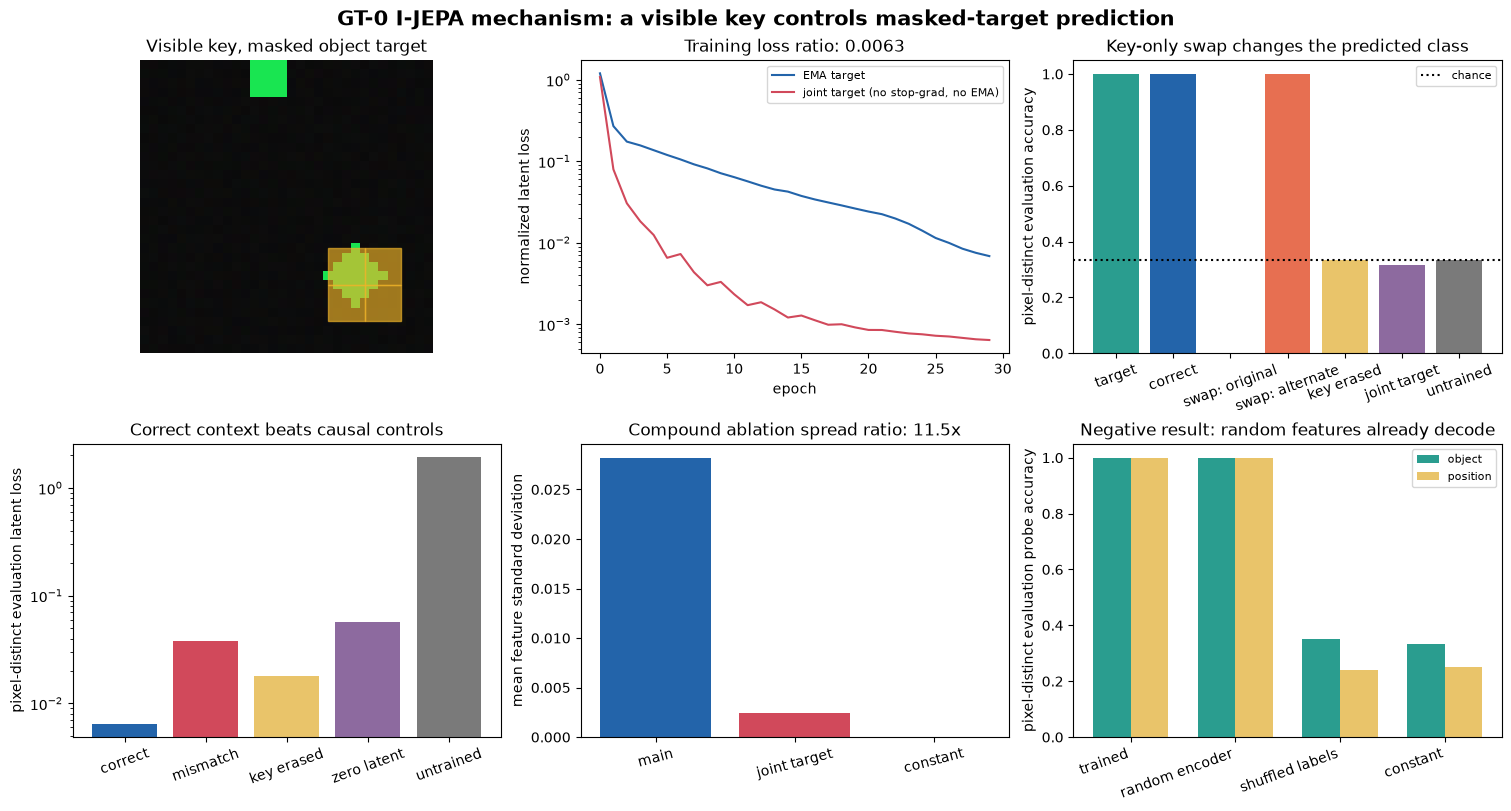

In [27]:
if not t.cuda.is_available():
    raise RuntimeError("Section 14.2 release result requires CUDA; no CPU fallback is used.")

print(f"Torch {t.__version__} | CUDA runtime {t.version.cuda} | {t.cuda.get_device_name()}")
seed_runs, seed_metrics = run_seed_suite(device="cuda", max_vram_gb=24.0)
run = seed_runs[0]
display(pd.DataFrame(seed_metrics["per_seed"]).round(4))

signature_table = pd.DataFrame(
    [
        {"condition": "target latent", "object_accuracy": run.prediction.target_object_accuracy, "latent_loss": np.nan},
        {"condition": "trained / correct context", "object_accuracy": run.prediction.predicted_object_accuracy, "latent_loss": run.prediction.latent_loss},
        {"condition": "original class after key swap", "object_accuracy": run.prediction.mismatched_context_object_accuracy, "latent_loss": run.prediction.mismatched_context_loss},
        {"condition": "alternate key class", "object_accuracy": run.prediction.alternate_key_object_accuracy, "latent_loss": run.prediction.mismatched_context_loss},
        {"condition": "trained / erased key", "object_accuracy": run.prediction.key_erased_context_object_accuracy, "latent_loss": run.prediction.key_erased_context_loss},
        {"condition": "trained / zero context", "object_accuracy": np.nan, "latent_loss": run.prediction.zero_context_loss},
        {"condition": "matched joint target / no EMA", "object_accuracy": run.joint_target_prediction.predicted_object_accuracy, "latent_loss": run.joint_target_prediction.latent_loss},
        {"condition": "untrained architecture", "object_accuracy": run.random_prediction.predicted_object_accuracy, "latent_loss": run.random_prediction.latent_loss},
    ]
)
display(signature_table.round(4))
print(
    f"feature spread: EMA={run.diagnostics.feature_std:.4f}, "
    f"compound ablation={run.joint_target_diagnostics.feature_std:.4f}; "
    f"exact pixel overlap={run.train_eval_exact_overlap}; "
    f"shared semantic templates={run.shared_semantic_template_count}/12; "
    f"non-key pixel diff={run.prediction.non_key_pixel_max_abs_diff:.1f}; "
    f"peak VRAM={run.peak_vram_gb:.3f} GiB"
)
print(
    "Probe warning: trained object/position "
    f"{run.probes.object_accuracy:.3f}/{run.probes.position_accuracy:.3f}, "
    "random encoder "
    f"{run.random_encoder_probes.object_accuracy:.3f}/{run.random_encoder_probes.position_accuracy:.3f}."
)
reference.plot_signature_result(run)
print("SIGNATURE PASSED for all three declared seeds.")
plt.show()


<details>
<summary>Expected output</summary>

On the pinned CUDA 13.2 run, correct-context prediction accuracy should be near `1.000`, original-class accuracy after a key-only swap near `0.000`, alternate-key accuracy near `1.000`, and untrained accuracy near chance. The non-key pixel difference must be exactly zero. Correct latent loss should be lower than key-mismatched and zero-context losses. Exact values are generated and checked below rather than treated as immutable constants.

</details>

<details>
<summary>Help</summary>

If prediction remains at chance, inspect the target mask first: every object pixel must be hidden and the key patch must remain visible. Then verify that target vectors are detached, EMA updates happen after the optimizer step, and the predictor scatters context into the correct patch positions.

</details>

<details>
<summary>Interpretation</summary>

The causal result is the paired prediction comparison, not the probe panel. Correct visible context determines the predicted target class on unseen scenes; replacing only the key changes the prediction to the alternate key's class and raises loss while every other pixel remains fixed. The untrained architecture rules out an architectural nearest-centroid shortcut. The matched compound target ablation can attain a small training-style loss while compressing feature scale and failing the held-out predictive criterion, demonstrating why low JEPA loss alone is insufficient.

The probe panel is deliberately a negative result: random transformer features already linearly decode this simple synthetic world. Therefore trained probe accuracy cannot support the headline claim.

`verification_report.json` is release evidence for CUDA/runtime/contracts only. It is not read by this notebook and is not part of the lesson's result.

</details>


## Try It Yourself: Choose the Wrong Key

Set `MISMATCH_SHIFT` to `1` or `2`. Both interventions preserve every non-key pixel and substitute only a different object's visible key. Predict the new class before running. You can also change `PLAY_SEED` to generate a disjoint world.


In [28]:
PLAY_SEED = 17
MISMATCH_SHIFT = 2  # choose 1 or 2; 0 is rejected because it is not an intervention

play_train = build_scene_dataset(10, seed=PLAY_SEED)
play_eval = build_scene_dataset(10, seed=PLAY_SEED + 50_000)
play_model, _, _ = _train_model(
    play_train,
    device=t.device("cuda"),
    seed=PLAY_SEED,
    epochs=30,
    batch_size=48,
    learning_rate=2e-3,
    ema_decay=0.995,
    joint_target_ablation=False,
)
play = evaluate_prediction(
    play_model,
    play_train,
    play_eval,
    device=t.device("cuda"),
    mismatch_shift=MISMATCH_SHIFT,
)
display(pd.DataFrame([
    {"context": "correct", "accuracy": play.predicted_object_accuracy, "loss": play.latent_loss},
    {"context": "swapped: original label", "accuracy": play.mismatched_context_object_accuracy, "loss": play.mismatched_context_loss},
    {"context": "swapped: alternate label", "accuracy": play.alternate_key_object_accuracy, "loss": play.mismatched_context_loss},
    {"context": "erased key", "accuracy": play.key_erased_context_object_accuracy, "loss": play.key_erased_context_loss},
    {"context": "zero latent", "accuracy": np.nan, "loss": play.zero_context_loss},
]).round(4))
print(
    f"correct={play.predicted_object_accuracy:.3f}, "
    f"original after key shift {MISMATCH_SHIFT}={play.mismatched_context_object_accuracy:.3f}, "
    f"alternate key={play.alternate_key_object_accuracy:.3f}, "
    f"non-key diff={play.non_key_pixel_max_abs_diff:.1f}, "
    f"loss ratio={play.mismatched_context_loss / play.latent_loss:.2f}x"
)


,context,accuracy,loss
0,correct,1.0000,0.0075
1,swapped: original label,0.0000,0.0869
2,swapped: alternate label,1.0000,0.0869
3,erased key,0.3333,0.0601
4,zero latent,NaN,0.0730


correct=1.000, original after key shift 2=0.000, alternate key=1.000, non-key diff=0.0, loss ratio=11.66x


<details>
<summary>Interpretation</summary>

A successful intervention changes the predicted object because the original object is completely absent from visible patches. If one shift behaves differently from the other, inspect class-centroid distances rather than averaging the anomaly away.

</details>

## Bonus: Hunt the Anomalies

1. The jointly optimized target can have lower latent loss but worse prediction. Plot its feature norm and centroid separation through training.
2. Random encoder probes are strong. Remove positional embeddings or randomize patch projection width and determine which easy factors survive.
3. Increase jitter until the exact 2x2 target no longer contains every object pixel. The leakage test should fail before the scientific claim does.
4. Remove the key patch while keeping the target fixed. Is zero context equivalent to ordinary noisy background context?
5. The signature reports every declared seed `0, 1, 2`. Add further seeds and report the worst case; do not hide an unstable seed behind a mean.

## Limitations and Paper Connection

This notebook demonstrates the I-JEPA mechanism on a deliberately exact world with an explicit predictive cue. It does not establish natural-image semantic learning, ImageNet transfer, scale behavior, multi-block masking parity, or parity with Meta's pretrained checkpoints. Our objective is unit-vector squared distance with learned positions and a single label-located target block. The released implementation uses layer-normalized targets, smooth-L1 loss, sine/cosine positions, and sampled multi-block targets. The object-position labels here select the mask, so this is not label-free pretraining. The original I-JEPA work uses large vision transformers and large-scale image data; those claims require a separate real-checkpoint reproduction.

- [I-JEPA paper](https://arxiv.org/abs/2301.08243)
- [Official I-JEPA code](https://github.com/facebookresearch/ijepa)
